# SmartCampus AI — SA-31 / SA-32 / SA-33 / SA-34
## Benchmark comparatif des modèles LLM — Notebook Kaggle de HA



In [1]:

!pip -q install -U "transformers>=4.52.4,<5" "huggingface_hub>=0.34,<1.0" hf_xet accelerate bitsandbytes sentencepiece peft
# Puis : Run > Restart Session, et relancer à partir de la cellule suivante.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.42.0 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import os, gc, re, json, time, random, warnings, math, platform, shutil
from pathlib import Path
OUTPUT_DIR = Path(os.environ.get("SMARTCAMPUS_OUTPUT_DIR", "/kaggle/working"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if Path("/kaggle").exists() and "HF_HOME" not in os.environ:
    os.environ["HF_HOME"] = "/tmp/hf_cache"
import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

def show_table(obj, max_rows=40):
    if isinstance(obj, pd.DataFrame):
        print(obj.head(max_rows).to_string(index=False))
        if len(obj) > max_rows:
            print(f"... {len(obj)-max_rows} lignes supplémentaires")
    elif isinstance(obj, pd.Series):
        print(obj.to_string())
    else:
        print(obj)

print("Python:", platform.python_version())
print("Pandas:", pd.__version__, "| NumPy:", np.__version__, "| PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM totale (GB):", round(torch.cuda.get_device_properties(0).total_memory/1024**3,2))
else:
    print("ATTENTION : activer GPU dans Kaggle > Settings > Accelerator.")
print("Sortie CSV :", OUTPUT_DIR)
print("Cache HF   :", os.environ.get("HF_HOME", "défaut"))
_cache_root = os.environ.get("HF_HOME") if Path(os.environ.get("HF_HOME","/nonexistent")).exists() else str(Path.home())
print("Espace libre cache (GB) :", round(shutil.disk_usage(_cache_root).free/1024**3,1))


Python: 3.13.16
Pandas: 2.3.3 | NumPy: 2.1.3 | PyTorch: 2.11.0+cu130
CUDA: True
GPU: Tesla T4
VRAM totale (GB): 14.56
Sortie CSV : /kaggle/working
Cache HF   : /tmp/hf_cache
Espace libre cache (GB) : 2514.2


In [3]:

HF_TOKEN = None
for _secret_name in ("Smartcampusai", "HF_TOKEN"):
    _value = None
    try:
        from kaggle_secrets import UserSecretsClient
        _value = UserSecretsClient().get_secret(_secret_name)
    except Exception:
        _value = os.environ.get(_secret_name)
    if _value and _value.strip():
        HF_TOKEN = _value.strip()
        print(f"Secret trouvé : {_secret_name}")
        break

if HF_TOKEN:
    try:
        from huggingface_hub import whoami
        _who = whoami(token=HF_TOKEN)
        os.environ["HF_TOKEN"] = HF_TOKEN
        print("Hugging Face : connecté en tant que", _who.get("name"))
    except Exception as e:
        print("ATTENTION : token Hugging Face invalide (", type(e).__name__, ").")
        print("Vérifie que le secret contient la VALEUR du token (hf_...), sans espace, et que le token est actif.")
        print("Le benchmark continue sans token : les modèles publics marcheront, pas les modèles gated.")
        HF_TOKEN = None
else:
    print("Aucun token trouvé. Vérifie : Add-ons > Secrets > le secret \"Smartcampusai\" existe ET est coché (Attached) pour CE notebook.")
    print("Les dépôts publics fonctionneront ; les dépôts gated (Gemma, Aya...) échoueront.")


Secret trouvé : Smartcampusai
Hugging Face : connecté en tant que Hadilabdelkafi


In [4]:
print("CUDA disponible :", torch.cuda.is_available())
if torch.cuda.is_available():
    for d in range(torch.cuda.device_count()):
        p = torch.cuda.get_device_properties(d)
        print(f"GPU {d} : {p.name} | {p.total_memory/1024**3:.1f} Go | capability {p.major}.{p.minor}")
    print("dtype de calcul :", compute_dtype() if "compute_dtype" in globals() else "défini plus bas")
else:
    print("ERREUR : aucun GPU détecté. Settings > Accelerator > GPU, puis relancer la session.")


CUDA disponible : True
GPU 0 : Tesla T4 | 14.6 Go | capability 7.5
GPU 1 : Tesla T4 | 14.6 Go | capability 7.5
dtype de calcul : défini plus bas


# SA-32 — Banque de 180 questions



In [5]:
DATA = [{'case_id': 'FR-ADM-01',
  'language': 'fr',
  'intent': 'admission',
  'question': "Quelles sont les étapes générales pour candidater à une formation de l'IIT après le baccalauréat ?",
  'expected_slots': [],
  'scenario': 'Admission générale IIT',
  'french_reformulation': "Quelles sont les étapes générales pour candidater à une formation de l'IIT après le "
                          'baccalauréat ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-ADM-02',
  'language': 'fr',
  'intent': 'admission',
  'question': "Je suis en terminale et je souhaite intégrer l'IIT. Quelles informations dois-je vérifier avant de "
              'déposer ma candidature ?',
  'expected_slots': ['level', 'institution'],
  'scenario': 'Admission IIT terminale',
  'french_reformulation': "Je suis en terminale et je souhaite intégrer l'IIT. Quelles informations dois-je vérifier "
                          'avant de déposer ma candidature ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-ADM-03',
  'language': 'fr',
  'intent': 'admission',
  'question': "Quelles démarches dois-je prévoir pour candidater à l'ISBS de Sfax après le bac ?",
  'expected_slots': ['institution'],
  'scenario': 'Admission ISBS',
  'french_reformulation': "Quelles démarches dois-je prévoir pour candidater à l'ISBS de Sfax après le bac ?",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-ADM-04',
  'language': 'fr',
  'intent': 'admission',
  'question': "Je possède déjà une licence en informatique. Puis-je me renseigner sur les voies d'accès à un cycle "
              "ingénieur à l'IIT ?",
  'expected_slots': ['level', 'preferred_domain', 'institution'],
  'scenario': 'Admission titulaire licence',
  'french_reformulation': "Je possède déjà une licence en informatique. Puis-je me renseigner sur les voies d'accès à "
                          "un cycle ingénieur à l'IIT ?",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-ADM-05',
  'language': 'fr',
  'intent': 'admission',
  'question': "Je viens d'un bac sciences expérimentales et je veux étudier la biotechnologie. Quelles informations "
              "d'admission dois-je demander à l'ISBS ?",
  'expected_slots': ['level', 'preferred_domain', 'institution'],
  'scenario': 'Admission biotechnologie',
  'french_reformulation': "Je viens d'un bac sciences expérimentales et je veux étudier la biotechnologie. Quelles "
                          "informations d'admission dois-je demander à l'ISBS ?",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-ADM-06',
  'language': 'fr',
  'intent': 'admission',
  'question': 'Je suis étudiant international. À qui dois-je demander les conditions et les pièces de candidature de '
              "l'IIT ?",
  'expected_slots': ['constraints', 'institution'],
  'scenario': 'Admission international',
  'french_reformulation': 'Je suis étudiant international. À qui dois-je demander les conditions et les pièces de '
                          "candidature de l'IIT ?",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-ADM-07',
  'language': 'fr',
  'intent': 'admission',
  'question': "Je souhaite changer d'établissement et rejoindre une formation de l'ISBS. Quelles règles dois-je faire "
              'confirmer ?',
  'expected_slots': ['institution'],
  'scenario': 'Admission transfert',
  'french_reformulation': "Je souhaite changer d'établissement et rejoindre une formation de l'ISBS. Quelles règles "
                          'dois-je faire confirmer ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-ADM-08',
  'language': 'fr',
  'intent': 'admission',
  'question': "Je veux connaître les conditions d'admission officielles pour 2026-2027. Peux-tu les confirmer sans "
              'supposer ?',
  'expected_slots': [],
  'scenario': 'Admission conditions année',
  'french_reformulation': "Je veux connaître les conditions d'admission officielles pour 2026-2027. Peux-tu les "
                          'confirmer sans supposer ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-ADM-09',
  'language': 'fr',
  'intent': 'admission',
  'question': "Ma candidature a été refusée et je voudrais savoir s'il existe une procédure de recours ou de "
              'réorientation. Que dois-je demander ?',
  'expected_slots': [],
  'scenario': 'Admission recours',
  'french_reformulation': "Ma candidature a été refusée et je voudrais savoir s'il existe une procédure de recours ou "
                          'de réorientation. Que dois-je demander ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-INF-01',
  'language': 'fr',
  'intent': 'information',
  'question': "Quelles licences informatiques l'IIT de Sfax présente-t-il : Réseaux et Cybersécurité, Systèmes "
              'Embarqués et IoT, Big Data, ou Génie Logiciel ?',
  'expected_slots': ['institution'],
  'scenario': 'Catalogue licences informatique IIT',
  'french_reformulation': "Quelles licences informatiques l'IIT de Sfax présente-t-il : Réseaux et Cybersécurité, "
                          'Systèmes Embarqués et IoT, Big Data, ou Génie Logiciel ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-INF-02',
  'language': 'fr',
  'intent': 'information',
  'question': "Je souhaite en savoir plus sur la Licence en Mécatronique et Systèmes Intelligents de l'IIT. Quelles "
              'informations dois-je consulter ?',
  'expected_slots': ['institution', 'target_program'],
  'scenario': 'Mécatronique IIT',
  'french_reformulation': 'Je souhaite en savoir plus sur la Licence en Mécatronique et Systèmes Intelligents de '
                          "l'IIT. Quelles informations dois-je consulter ?",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-INF-03',
  'language': 'fr',
  'intent': 'information',
  'question': 'Quelles formations en systèmes électriques intelligents et énergies renouvelables sont affichées par '
              "l'IIT ?",
  'expected_slots': ['institution', 'target_program'],
  'scenario': 'Energies renouvelables IIT',
  'french_reformulation': 'Quelles formations en systèmes électriques intelligents et énergies renouvelables sont '
                          "affichées par l'IIT ?",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-INF-04',
  'language': 'fr',
  'intent': 'information',
  'question': "Quelles filières ingénieur l'IIT présente-t-il, notamment en génie informatique, génie civil et génie "
              'industriel ?',
  'expected_slots': ['institution'],
  'scenario': 'Ingénierie IIT',
  'french_reformulation': "Quelles filières ingénieur l'IIT présente-t-il, notamment en génie informatique, génie "
                          'civil et génie industriel ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-INF-05',
  'language': 'fr',
  'intent': 'information',
  'question': "Quelles licences sont proposées par l'ISBS de Sfax en biotechnologie et en génie biomédical ?",
  'expected_slots': ['institution'],
  'scenario': 'Licences ISBS',
  'french_reformulation': "Quelles licences sont proposées par l'ISBS de Sfax en biotechnologie et en génie biomédical "
                          '?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-INF-06',
  'language': 'fr',
  'intent': 'information',
  'question': "L'ISBS propose-t-il des formations en ingénierie des procédés industriels, mesures et instrumentation ?",
  'expected_slots': ['institution'],
  'scenario': 'Procédés instrumentation ISBS',
  'french_reformulation': "L'ISBS propose-t-il des formations en ingénierie des procédés industriels, mesures et "
                          'instrumentation ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-INF-07',
  'language': 'fr',
  'intent': 'information',
  'question': 'Je cherche des informations sur les formations ISBS en Sciences du Vivant et Environnement et en '
              'Sciences et Technologies Alimentaires.',
  'expected_slots': ['institution'],
  'scenario': 'Vivant alimentation ISBS',
  'french_reformulation': 'Je cherche des informations sur les formations ISBS en Sciences du Vivant et Environnement '
                          'et en Sciences et Technologies Alimentaires.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-INF-08',
  'language': 'fr',
  'intent': 'information',
  'question': "Quels mastères professionnels l'ISBS affiche-t-il dans les domaines biotechnologie-santé, génie "
              'biomédical et environnement ?',
  'expected_slots': ['institution'],
  'scenario': 'Masters ISBS',
  'french_reformulation': "Quels mastères professionnels l'ISBS affiche-t-il dans les domaines biotechnologie-santé, "
                          'génie biomédical et environnement ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-INF-09',
  'language': 'fr',
  'intent': 'information',
  'question': "Où puis-je vérifier la liste officielle et actualisée des formations de l'IIT et de l'ISBS ?",
  'expected_slots': [],
  'scenario': 'Source catalogue officielle',
  'french_reformulation': "Où puis-je vérifier la liste officielle et actualisée des formations de l'IIT et de l'ISBS "
                          '?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-ORI-01',
  'language': 'fr',
  'intent': 'orientation',
  'question': "Je suis en bac mathématiques, j'aime les mathématiques et la programmation et je vise le génie "
              'logiciel. Quelles pistes IIT explorer ?',
  'expected_slots': ['level', 'favorite_subjects', 'career_goal', 'institution'],
  'scenario': 'Orientation bac maths logiciel',
  'french_reformulation': "Je suis en bac mathématiques, j'aime les mathématiques et la programmation et je vise le "
                          'génie logiciel. Quelles pistes IIT explorer ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-ORI-02',
  'language': 'fr',
  'intent': 'orientation',
  'question': "Je suis en bac sciences expérimentales, j'aime la biologie et les manipulations en laboratoire. Quelles "
              'pistes ISBS examiner ?',
  'expected_slots': ['level', 'favorite_subjects', 'preferred_domain', 'institution'],
  'scenario': 'Orientation sciences biologie',
  'french_reformulation': "Je suis en bac sciences expérimentales, j'aime la biologie et les manipulations en "
                          'laboratoire. Quelles pistes ISBS examiner ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-ORI-03',
  'language': 'fr',
  'intent': 'orientation',
  'question': "J'aime Linux, les réseaux et la cybersécurité. Aide-moi à identifier les formations IIT qui "
              'correspondent à mes intérêts.',
  'expected_slots': ['favorite_subjects', 'preferred_domain', 'institution'],
  'scenario': 'Orientation cyber',
  'french_reformulation': "J'aime Linux, les réseaux et la cybersécurité. Aide-moi à identifier les formations IIT qui "
                          'correspondent à mes intérêts.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-ORI-04',
  'language': 'fr',
  'intent': 'orientation',
  'question': "Je suis attiré par les capteurs, l'électronique, la robotique et la programmation. Est-ce que la "
              'mécatronique pourrait me convenir ?',
  'expected_slots': ['favorite_subjects', 'preferred_domain'],
  'scenario': 'Orientation mécatronique',
  'french_reformulation': "Je suis attiré par les capteurs, l'électronique, la robotique et la programmation. Est-ce "
                          'que la mécatronique pourrait me convenir ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-ORI-05',
  'language': 'fr',
  'intent': 'orientation',
  'question': "J'aime organiser le travail, optimiser une production et analyser des processus. Aide-moi à examiner le "
              'génie industriel.',
  'expected_slots': ['favorite_subjects', 'preferred_domain'],
  'scenario': 'Orientation industriel',
  'french_reformulation': "J'aime organiser le travail, optimiser une production et analyser des processus. Aide-moi à "
                          'examiner le génie industriel.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-ORI-06',
  'language': 'fr',
  'intent': 'orientation',
  'question': "Je m'intéresse aux équipements médicaux et aux technologies de santé. Quelles pistes de formation à "
              "l'ISBS pourrais-je comparer ?",
  'expected_slots': ['favorite_subjects', 'preferred_domain', 'institution'],
  'scenario': 'Orientation biomédical',
  'french_reformulation': "Je m'intéresse aux équipements médicaux et aux technologies de santé. Quelles pistes de "
                          "formation à l'ISBS pourrais-je comparer ?",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-ORI-07',
  'language': 'fr',
  'intent': 'orientation',
  'question': 'Je préfère apprendre avec des projets et des applications concrètes. Quelles questions dois-tu me poser '
              'avant de recommander une formation ?',
  'expected_slots': ['learning_preference'],
  'scenario': 'Orientation pratique',
  'french_reformulation': 'Je préfère apprendre avec des projets et des applications concrètes. Quelles questions '
                          'dois-tu me poser avant de recommander une formation ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-ORI-08',
  'language': 'fr',
  'intent': 'orientation',
  'question': "J'aime les mathématiques mais je ne sais pas si je préfère la data, les réseaux ou les systèmes "
              "embarqués. Comment m'orienter ?",
  'expected_slots': ['favorite_subjects'],
  'scenario': 'Orientation choix domaine',
  'french_reformulation': "J'aime les mathématiques mais je ne sais pas si je préfère la data, les réseaux ou les "
                          "systèmes embarqués. Comment m'orienter ?",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-ORI-09',
  'language': 'fr',
  'intent': 'orientation',
  'question': 'Je veux une formation qui corresponde à mes matières préférées, à mes résultats et à mon projet '
              'professionnel. Commence par recueillir mon profil.',
  'expected_slots': [],
  'scenario': 'Orientation profil progressif',
  'french_reformulation': 'Je veux une formation qui corresponde à mes matières préférées, à mes résultats et à mon '
                          'projet professionnel. Commence par recueillir mon profil.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-COM-01',
  'language': 'fr',
  'intent': 'comparison',
  'question': "Compare les licences Réseaux et Cybersécurité et Big Data et Analyse de Données à l'IIT, sans inventer "
              'les programmes détaillés.',
  'expected_slots': [],
  'scenario': 'Comparaison licences IT',
  'french_reformulation': "Compare les licences Réseaux et Cybersécurité et Big Data et Analyse de Données à l'IIT, "
                          'sans inventer les programmes détaillés.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-COM-02',
  'language': 'fr',
  'intent': 'comparison',
  'question': 'Quelle différence générale dois-je examiner entre Génie Logiciel et Systèmes Intelligents et Systèmes '
              'Embarqués et IoT ?',
  'expected_slots': [],
  'scenario': 'Comparaison logiciel IoT',
  'french_reformulation': 'Quelle différence générale dois-je examiner entre Génie Logiciel et Systèmes Intelligents '
                          'et Systèmes Embarqués et IoT ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-COM-03',
  'language': 'fr',
  'intent': 'comparison',
  'question': "Je balance entre une Licence et le Cycle Préparatoire de l'IIT. Pose-moi les questions utiles avant de "
              'comparer.',
  'expected_slots': [],
  'scenario': 'Comparaison licence prepa',
  'french_reformulation': "Je balance entre une Licence et le Cycle Préparatoire de l'IIT. Pose-moi les questions "
                          'utiles avant de comparer.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-COM-04',
  'language': 'fr',
  'intent': 'comparison',
  'question': 'Compare les domaines du génie informatique et du génie industriel selon les intérêts et les activités '
              'professionnelles.',
  'expected_slots': [],
  'scenario': 'Comparaison domaines ingenieur',
  'french_reformulation': 'Compare les domaines du génie informatique et du génie industriel selon les intérêts et les '
                          'activités professionnelles.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-COM-05',
  'language': 'fr',
  'intent': 'comparison',
  'question': "Je suis indécis entre Génie Biomédical et Biotechnologie à l'ISBS. Quels critères personnels dois-je "
              'comparer ?',
  'expected_slots': [],
  'scenario': 'Comparaison filières ISBS',
  'french_reformulation': "Je suis indécis entre Génie Biomédical et Biotechnologie à l'ISBS. Quels critères "
                          'personnels dois-je comparer ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-COM-06',
  'language': 'fr',
  'intent': 'comparison',
  'question': 'Quelle différence de domaine existe entre Mesures et Instrumentation et Ingénierie des Procédés '
              "Industriels à l'ISBS ?",
  'expected_slots': [],
  'scenario': 'Comparaison mesures procédés',
  'french_reformulation': 'Quelle différence de domaine existe entre Mesures et Instrumentation et Ingénierie des '
                          "Procédés Industriels à l'ISBS ?",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-COM-07',
  'language': 'fr',
  'intent': 'comparison',
  'question': 'Compare une formation orientée cybersécurité et une formation orientée systèmes embarqués selon mes '
              'goûts pour le logiciel et le matériel.',
  'expected_slots': [],
  'scenario': 'Comparaison cyber embarqué',
  'french_reformulation': 'Compare une formation orientée cybersécurité et une formation orientée systèmes embarqués '
                          'selon mes goûts pour le logiciel et le matériel.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-COM-08',
  'language': 'fr',
  'intent': 'comparison',
  'question': "Je préfère les sciences du vivant, mais je m'intéresse aussi aux technologies alimentaires. Aide-moi à "
              "comparer ces orientations à l'ISBS.",
  'expected_slots': [],
  'scenario': 'Comparaison vivant alimentaire',
  'french_reformulation': "Je préfère les sciences du vivant, mais je m'intéresse aussi aux technologies alimentaires. "
                          "Aide-moi à comparer ces orientations à l'ISBS.",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-COM-09',
  'language': 'fr',
  'intent': 'comparison',
  'question': 'Compare IIT et ISBS uniquement sur les domaines que je te précise, et indique les informations qui '
              'doivent être vérifiées.',
  'expected_slots': [],
  'scenario': 'Comparaison institutions',
  'french_reformulation': 'Compare IIT et ISBS uniquement sur les domaines que je te précise, et indique les '
                          'informations qui doivent être vérifiées.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-PRO-01',
  'language': 'fr',
  'intent': 'profile',
  'question': "Je suis en terminale bac mathématiques, j'ai 15 en maths, 11 en physique et 14 en informatique. Résume "
              'mon profil.',
  'expected_slots': ['level', 'grades'],
  'scenario': 'Profil bac math notes',
  'french_reformulation': "Je suis en terminale bac mathématiques, j'ai 15 en maths, 11 en physique et 14 en "
                          'informatique. Résume mon profil.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-PRO-02',
  'language': 'fr',
  'intent': 'profile',
  'question': "Mon bac est sciences expérimentales. J'aime la biologie et la chimie et je préfère le travail en "
              'laboratoire.',
  'expected_slots': ['level', 'favorite_subjects', 'learning_preference'],
  'scenario': 'Profil sciences',
  'french_reformulation': "Mon bac est sciences expérimentales. J'aime la biologie et la chimie et je préfère le "
                          'travail en laboratoire.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-PRO-03',
  'language': 'fr',
  'intent': 'profile',
  'question': "J'ai un bac technique, je suis à l'aise en électronique et en mécanique et je préfère les projets "
              'pratiques.',
  'expected_slots': ['level', 'favorite_subjects', 'learning_preference'],
  'scenario': 'Profil technique',
  'french_reformulation': "J'ai un bac technique, je suis à l'aise en électronique et en mécanique et je préfère les "
                          'projets pratiques.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-PRO-04',
  'language': 'fr',
  'intent': 'profile',
  'question': 'Je possède une licence en informatique et je souhaite poursuivre mes études en ingénierie.',
  'expected_slots': ['level', 'preferred_domain'],
  'scenario': 'Profil bac plus licence',
  'french_reformulation': 'Je possède une licence en informatique et je souhaite poursuivre mes études en ingénierie.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-PRO-05',
  'language': 'fr',
  'intent': 'profile',
  'question': "Mes points forts sont les mathématiques et la logique. J'ai davantage de difficultés en physique.",
  'expected_slots': ['favorite_subjects', 'learning_preference'],
  'scenario': 'Profil forces difficultés',
  'french_reformulation': "Mes points forts sont les mathématiques et la logique. J'ai davantage de difficultés en "
                          'physique.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-PRO-06',
  'language': 'fr',
  'intent': 'profile',
  'question': "J'ai obtenu 13 en maths, 16 en SVT et 15 en chimie. J'aime la biotechnologie et la santé.",
  'expected_slots': ['grades', 'favorite_subjects', 'preferred_domain'],
  'scenario': 'Profil notes biotech',
  'french_reformulation': "J'ai obtenu 13 en maths, 16 en SVT et 15 en chimie. J'aime la biotechnologie et la santé.",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-PRO-07',
  'language': 'fr',
  'intent': 'profile',
  'question': "Je suis en bac informatique, je programme un peu en Python et je m'intéresse à la data science.",
  'expected_slots': ['level', 'favorite_subjects', 'preferred_domain'],
  'scenario': 'Profil informatique data',
  'french_reformulation': "Je suis en bac informatique, je programme un peu en Python et je m'intéresse à la data "
                          'science.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-PRO-08',
  'language': 'fr',
  'intent': 'profile',
  'question': 'Je ne connais pas encore mon métier futur, mais je sais que je veux une formation appliquée et proche '
              'des projets.',
  'expected_slots': ['career_goal', 'learning_preference'],
  'scenario': 'Profil sans projet',
  'french_reformulation': 'Je ne connais pas encore mon métier futur, mais je sais que je veux une formation appliquée '
                          'et proche des projets.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-PRO-09',
  'language': 'fr',
  'intent': 'profile',
  'question': "Je dois travailler à côté de mes études et j'ai besoin de connaître les horaires et modalités avant de "
              'choisir.',
  'expected_slots': ['constraints'],
  'scenario': 'Profil contraintes',
  'french_reformulation': "Je dois travailler à côté de mes études et j'ai besoin de connaître les horaires et "
                          'modalités avant de choisir.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-PRE-01',
  'language': 'fr',
  'intent': 'pre_registration',
  'question': "Je souhaite préparer une préinscription à l'IIT en Génie Logiciel. Quelles informations personnelles et "
              'scolaires dois-je rassembler ?',
  'expected_slots': ['institution', 'target_program'],
  'scenario': 'Préinscription IIT logiciel',
  'french_reformulation': "Je souhaite préparer une préinscription à l'IIT en Génie Logiciel. Quelles informations "
                          'personnelles et scolaires dois-je rassembler ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-PRE-02',
  'language': 'fr',
  'intent': 'pre_registration',
  'question': "Je veux déposer une candidature à l'ISBS en Génie Biomédical. Aide-moi à préparer les informations "
              'nécessaires.',
  'expected_slots': ['institution', 'target_program'],
  'scenario': 'Préinscription ISBS biomédical',
  'french_reformulation': "Je veux déposer une candidature à l'ISBS en Génie Biomédical. Aide-moi à préparer les "
                          'informations nécessaires.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-PRE-03',
  'language': 'fr',
  'intent': 'pre_registration',
  'question': "Je suis intéressé par la Licence Réseaux et Cybersécurité à l'IIT. Quelle est la prochaine étape pour "
              'préparer mon dossier ?',
  'expected_slots': ['institution', 'target_program'],
  'scenario': 'Préinscription cyber',
  'french_reformulation': "Je suis intéressé par la Licence Réseaux et Cybersécurité à l'IIT. Quelle est la prochaine "
                          'étape pour préparer mon dossier ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-PRE-04',
  'language': 'fr',
  'intent': 'pre_registration',
  'question': 'Je ne connais pas encore le nom exact de la formation, mais je voudrais commencer mon dossier de '
              "candidature à l'IIT.",
  'expected_slots': ['institution'],
  'scenario': 'Préinscription sans programme',
  'french_reformulation': 'Je ne connais pas encore le nom exact de la formation, mais je voudrais commencer mon '
                          "dossier de candidature à l'IIT.",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-PRE-05',
  'language': 'fr',
  'intent': 'pre_registration',
  'question': "Quelles informations dois-je vérifier avant de soumettre une préinscription en biotechnologie à l'ISBS "
              '?',
  'expected_slots': ['institution', 'target_program'],
  'scenario': 'Préinscription biotech',
  'french_reformulation': 'Quelles informations dois-je vérifier avant de soumettre une préinscription en '
                          "biotechnologie à l'ISBS ?",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-PRE-06',
  'language': 'fr',
  'intent': 'pre_registration',
  'question': 'Je souhaite préparer une préinscription, mais je ne veux pas transmettre mes données personnelles avant '
              'de connaître leur utilisation.',
  'expected_slots': ['constraints'],
  'scenario': 'Préinscription consentement',
  'french_reformulation': 'Je souhaite préparer une préinscription, mais je ne veux pas transmettre mes données '
                          'personnelles avant de connaître leur utilisation.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-PRE-07',
  'language': 'fr',
  'intent': 'pre_registration',
  'question': 'Peux-tu me guider étape par étape pour préparer une candidature, sans prétendre que tu as envoyé le '
              'dossier ?',
  'expected_slots': [],
  'scenario': 'Préinscription limites outils',
  'french_reformulation': 'Peux-tu me guider étape par étape pour préparer une candidature, sans prétendre que tu as '
                          'envoyé le dossier ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-PRE-08',
  'language': 'fr',
  'intent': 'pre_registration',
  'question': "J'ai déjà envoyé une demande de préinscription. Quelles informations dois-je demander au service "
              'concerné pour suivre son état ?',
  'expected_slots': [],
  'scenario': 'Suivi dossier',
  'french_reformulation': "J'ai déjà envoyé une demande de préinscription. Quelles informations dois-je demander au "
                          'service concerné pour suivre son état ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-PRE-09',
  'language': 'fr',
  'intent': 'pre_registration',
  'question': 'Je veux comparer deux formations avant de finaliser ma préinscription. Aide-moi à ne pas choisir trop '
              'vite.',
  'expected_slots': [],
  'scenario': 'Préinscription choix',
  'french_reformulation': 'Je veux comparer deux formations avant de finaliser ma préinscription. Aide-moi à ne pas '
                          'choisir trop vite.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-REF-01',
  'language': 'fr',
  'intent': 'reformulation',
  'question': "Reformule ma demande de manière claire : je veux étudier l'informatique à Sfax mais je ne sais pas quel "
              'parcours choisir.',
  'expected_slots': [],
  'scenario': 'Reformulation demande informatique',
  'french_reformulation': "Reformule ma demande de manière claire : je veux étudier l'informatique à Sfax mais je ne "
                          'sais pas quel parcours choisir.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-REF-02',
  'language': 'fr',
  'intent': 'reformulation',
  'question': "Je vais expliquer mon besoin avec mes propres mots : j'aime les machines, les capteurs et un peu de "
              'code. Reformule ce que je cherche.',
  'expected_slots': [],
  'scenario': 'Reformulation technologie',
  'french_reformulation': "Je vais expliquer mon besoin avec mes propres mots : j'aime les machines, les capteurs et "
                          'un peu de code. Reformule ce que je cherche.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-REF-03',
  'language': 'fr',
  'intent': 'reformulation',
  'question': "Peux-tu reformuler cette question pour un conseiller : quelles sont les conditions d'accès à l'ISBS ?",
  'expected_slots': [],
  'scenario': 'Reformulation question ISBS',
  'french_reformulation': "Peux-tu reformuler cette question pour un conseiller : quelles sont les conditions d'accès "
                          "à l'ISBS ?",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-REF-04',
  'language': 'fr',
  'intent': 'reformulation',
  'question': 'Reformule en français simple : n7eb na9ra informatique ama mazelt m7ayer.',
  'expected_slots': [],
  'scenario': 'Reformulation Arabizi',
  'french_reformulation': 'Reformule en français simple : n7eb na9ra informatique ama mazelt m7ayer.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-REF-05',
  'language': 'fr',
  'intent': 'reformulation',
  'question': 'Je veux demander la différence entre licence et cycle ingénieur, mais ma phrase est maladroite. '
              'Aide-moi à la corriger.',
  'expected_slots': [],
  'scenario': 'Reformulation comparaison',
  'french_reformulation': 'Je veux demander la différence entre licence et cycle ingénieur, mais ma phrase est '
                          'maladroite. Aide-moi à la corriger.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-REF-06',
  'language': 'fr',
  'intent': 'reformulation',
  'question': 'Transforme mon message en une question précise : je cherche une formation en santé et technologie.',
  'expected_slots': [],
  'scenario': 'Reformulation biomédical',
  'french_reformulation': 'Transforme mon message en une question précise : je cherche une formation en santé et '
                          'technologie.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-REF-07',
  'language': 'fr',
  'intent': 'reformulation',
  'question': 'Voici ma phrase : je veux une formation pratique et pas trop théorique. Reformule-la sans changer le '
              'sens.',
  'expected_slots': [],
  'scenario': 'Reformulation apprentissage',
  'french_reformulation': 'Voici ma phrase : je veux une formation pratique et pas trop théorique. Reformule-la sans '
                          'changer le sens.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-REF-08',
  'language': 'fr',
  'intent': 'reformulation',
  'question': "Reformule cette demande poliment : donnez-moi les frais et les dates d'inscription exacts.",
  'expected_slots': [],
  'scenario': 'Reformulation frais',
  'french_reformulation': "Reformule cette demande poliment : donnez-moi les frais et les dates d'inscription exacts.",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-REF-09',
  'language': 'fr',
  'intent': 'reformulation',
  'question': "Corrige ma formulation sans répondre à ma place : je sais pas quoi faire après le bac et j'aime les "
              'sciences.',
  'expected_slots': [],
  'scenario': 'Reformulation après bac',
  'french_reformulation': 'Corrige ma formulation sans répondre à ma place : je sais pas quoi faire après le bac et '
                          "j'aime les sciences.",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-AMB-01',
  'language': 'fr',
  'intent': 'ambiguous',
  'question': "Je veux faire informatique, mais pas vraiment informatique. Qu'est-ce que tu me proposes ?",
  'expected_slots': [],
  'scenario': 'Ambigu informatique',
  'french_reformulation': "Je veux faire informatique, mais pas vraiment informatique. Qu'est-ce que tu me proposes ?",
  'is_ambiguous': True,
  'should_ask_clarification': True},
 {'case_id': 'FR-AMB-02',
  'language': 'fr',
  'intent': 'ambiguous',
  'question': 'Je veux une formation courte, longue si possible, et qui me laisse beaucoup de temps.',
  'expected_slots': [],
  'scenario': 'Ambigu durée',
  'french_reformulation': 'Je veux une formation courte, longue si possible, et qui me laisse beaucoup de temps.',
  'is_ambiguous': True,
  'should_ask_clarification': True},
 {'case_id': 'FR-AMB-03',
  'language': 'fr',
  'intent': 'ambiguous',
  'question': "Je veux m'inscrire là-bas dans cette spécialité, tu vois laquelle.",
  'expected_slots': [],
  'scenario': 'Ambigu référent',
  'french_reformulation': "Je veux m'inscrire là-bas dans cette spécialité, tu vois laquelle.",
  'is_ambiguous': True,
  'should_ask_clarification': True},
 {'case_id': 'FR-AMB-04',
  'language': 'fr',
  'intent': 'ambiguous',
  'question': "Je préfère les sciences, mais je n'aime ni les maths, ni la physique, ni la biologie. Quel domaine "
              'choisir ?',
  'expected_slots': [],
  'scenario': 'Ambigu contradiction',
  'french_reformulation': "Je préfère les sciences, mais je n'aime ni les maths, ni la physique, ni la biologie. Quel "
                          'domaine choisir ?',
  'is_ambiguous': True,
  'should_ask_clarification': True},
 {'case_id': 'FR-AMB-05',
  'language': 'fr',
  'intent': 'ambiguous',
  'question': 'Je veux le parcours le plus facile mais aussi le plus avancé et le plus pratique.',
  'expected_slots': [],
  'scenario': 'Ambigu critères',
  'french_reformulation': 'Je veux le parcours le plus facile mais aussi le plus avancé et le plus pratique.',
  'is_ambiguous': True,
  'should_ask_clarification': True},
 {'case_id': 'FR-AMB-06',
  'language': 'fr',
  'intent': 'ambiguous',
  'question': "Mon ami m'a conseillé cette formation. Est-ce que c'est la meilleure pour moi ?",
  'expected_slots': [],
  'scenario': 'Ambigu sans profil',
  'french_reformulation': "Mon ami m'a conseillé cette formation. Est-ce que c'est la meilleure pour moi ?",
  'is_ambiguous': True,
  'should_ask_clarification': True},
 {'case_id': 'FR-AMB-07',
  'language': 'fr',
  'intent': 'ambiguous',
  'question': "Je veux travailler dans la technologie, mais je ne sais pas si je parle de santé, d'informatique ou "
              "d'industrie.",
  'expected_slots': [],
  'scenario': 'Ambigu technologie',
  'french_reformulation': 'Je veux travailler dans la technologie, mais je ne sais pas si je parle de santé, '
                          "d'informatique ou d'industrie.",
  'is_ambiguous': True,
  'should_ask_clarification': True},
 {'case_id': 'FR-AMB-08',
  'language': 'fr',
  'intent': 'ambiguous',
  'question': "Je veux changer mon choix, mais je ne sais plus lequel j'avais fait.",
  'expected_slots': [],
  'scenario': 'Ambigu contexte manquant',
  'french_reformulation': "Je veux changer mon choix, mais je ne sais plus lequel j'avais fait.",
  'is_ambiguous': True,
  'should_ask_clarification': True},
 {'case_id': 'FR-AMB-09',
  'language': 'fr',
  'intent': 'ambiguous',
  'question': "Donne-moi les informations pour l'année prochaine, mais je ne sais pas encore quelle formation ni "
              'quelle année exacte.',
  'expected_slots': [],
  'scenario': 'Ambigu admission',
  'french_reformulation': "Donne-moi les informations pour l'année prochaine, mais je ne sais pas encore quelle "
                          'formation ni quelle année exacte.',
  'is_ambiguous': True,
  'should_ask_clarification': True},
 {'case_id': 'FR-QUI-01',
  'language': 'fr',
  'intent': 'quiz',
  'question': 'Prépare trois questions progressives en algorithmique pour vérifier mes bases avant une orientation '
              'informatique.',
  'expected_slots': ['preferred_domain'],
  'scenario': 'QCM algorithmique',
  'french_reformulation': 'Prépare trois questions progressives en algorithmique pour vérifier mes bases avant une '
                          'orientation informatique.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-QUI-02',
  'language': 'fr',
  'intent': 'quiz',
  'question': 'Je veux un petit QCM sur les réseaux informatiques, avec correction après ma réponse.',
  'expected_slots': ['preferred_domain'],
  'scenario': 'QCM réseaux',
  'french_reformulation': 'Je veux un petit QCM sur les réseaux informatiques, avec correction après ma réponse.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-QUI-03',
  'language': 'fr',
  'intent': 'quiz',
  'question': "Prépare un QCM de biologie générale pour m'aider à identifier les notions que je maîtrise.",
  'expected_slots': ['preferred_domain'],
  'scenario': 'QCM biologie',
  'french_reformulation': "Prépare un QCM de biologie générale pour m'aider à identifier les notions que je maîtrise.",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-QUI-04',
  'language': 'fr',
  'intent': 'quiz',
  'question': "Teste mes connaissances de base en mathématiques utiles pour des études d'ingénieur.",
  'expected_slots': [],
  'scenario': 'QCM maths',
  'french_reformulation': "Teste mes connaissances de base en mathématiques utiles pour des études d'ingénieur.",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-QUI-05',
  'language': 'fr',
  'intent': 'quiz',
  'question': "Je voudrais un quiz sur l'électronique et les systèmes embarqués, niveau débutant.",
  'expected_slots': ['preferred_domain'],
  'scenario': 'QCM électronique',
  'french_reformulation': "Je voudrais un quiz sur l'électronique et les systèmes embarqués, niveau débutant.",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-QUI-06',
  'language': 'fr',
  'intent': 'quiz',
  'question': 'Pose-moi cinq questions sur les notions fondamentales de cybersécurité, une par une.',
  'expected_slots': ['preferred_domain'],
  'scenario': 'QCM cyber',
  'french_reformulation': 'Pose-moi cinq questions sur les notions fondamentales de cybersécurité, une par une.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-QUI-07',
  'language': 'fr',
  'intent': 'quiz',
  'question': "Je veux évaluer mes connaissances en chimie et en biotechnologie avant de choisir l'ISBS.",
  'expected_slots': ['preferred_domain', 'institution'],
  'scenario': 'QCM biotech',
  'french_reformulation': "Je veux évaluer mes connaissances en chimie et en biotechnologie avant de choisir l'ISBS.",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-QUI-08',
  'language': 'fr',
  'intent': 'quiz',
  'question': 'Prépare une question pour tester ma logique, puis explique la réponse si je me trompe.',
  'expected_slots': [],
  'scenario': 'QCM logique',
  'french_reformulation': 'Prépare une question pour tester ma logique, puis explique la réponse si je me trompe.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-QUI-09',
  'language': 'fr',
  'intent': 'quiz',
  'question': "Je souhaite un QCM d'orientation qui m'aide à identifier mes intérêts, pas un examen officiel.",
  'expected_slots': [],
  'scenario': 'QCM orientation',
  'french_reformulation': "Je souhaite un QCM d'orientation qui m'aide à identifier mes intérêts, pas un examen "
                          'officiel.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-APP-01',
  'language': 'fr',
  'intent': 'appointment',
  'question': "Je souhaite prendre rendez-vous avec un responsable des admissions de l'IIT. Comment préparer ma "
              'demande ?',
  'expected_slots': ['institution'],
  'scenario': 'Rendez-vous IIT',
  'french_reformulation': "Je souhaite prendre rendez-vous avec un responsable des admissions de l'IIT. Comment "
                          'préparer ma demande ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-APP-02',
  'language': 'fr',
  'intent': 'appointment',
  'question': "Je veux parler à un responsable de l'ISBS pour vérifier une information sur une licence.",
  'expected_slots': ['institution'],
  'scenario': 'Rendez-vous ISBS',
  'french_reformulation': "Je veux parler à un responsable de l'ISBS pour vérifier une information sur une licence.",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-APP-03',
  'language': 'fr',
  'intent': 'appointment',
  'question': 'Je voudrais un entretien avec un conseiller pour discuter de mon profil et de mon orientation.',
  'expected_slots': [],
  'scenario': 'Entretien orientation',
  'french_reformulation': 'Je voudrais un entretien avec un conseiller pour discuter de mon profil et de mon '
                          'orientation.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-APP-04',
  'language': 'fr',
  'intent': 'appointment',
  'question': "Je souhaite confirmer les horaires d'accueil du service d'admission. Où dois-je vérifier ?",
  'expected_slots': [],
  'scenario': 'Contact horaires',
  'french_reformulation': "Je souhaite confirmer les horaires d'accueil du service d'admission. Où dois-je vérifier ?",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-APP-05',
  'language': 'fr',
  'intent': 'appointment',
  'question': "Je veux demander un rendez-vous en présentiel à Sfax, mais je n'ai pas encore de date.",
  'expected_slots': ['constraints'],
  'scenario': 'Rendez-vous présentiel',
  'french_reformulation': "Je veux demander un rendez-vous en présentiel à Sfax, mais je n'ai pas encore de date.",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-APP-06',
  'language': 'fr',
  'intent': 'appointment',
  'question': 'Je ne peux pas venir sur place. Est-il possible de demander un échange à distance avec un responsable ?',
  'expected_slots': ['constraints'],
  'scenario': 'Rendez-vous distant',
  'french_reformulation': 'Je ne peux pas venir sur place. Est-il possible de demander un échange à distance avec un '
                          'responsable ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-APP-07',
  'language': 'fr',
  'intent': 'appointment',
  'question': 'Je souhaite parler à un responsable académique pour vérifier si mon projet correspond à une formation.',
  'expected_slots': [],
  'scenario': 'Rendez-vous académique',
  'french_reformulation': 'Je souhaite parler à un responsable académique pour vérifier si mon projet correspond à une '
                          'formation.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-APP-08',
  'language': 'fr',
  'intent': 'appointment',
  'question': "J'ai une question officielle sur les conditions d'admission et je préfère une confirmation humaine.",
  'expected_slots': [],
  'scenario': 'Escalade humaine',
  'french_reformulation': "J'ai une question officielle sur les conditions d'admission et je préfère une confirmation "
                          'humaine.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'FR-APP-09',
  'language': 'fr',
  'intent': 'appointment',
  'question': 'Je veux modifier un rendez-vous déjà demandé. Quelle démarche dois-je suivre auprès du service ?',
  'expected_slots': [],
  'scenario': 'Modifier rendez-vous',
  'french_reformulation': 'Je veux modifier un rendez-vous déjà demandé. Quelle démarche dois-je suivre auprès du '
                          'service ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'TN_AR-ADM-01',
  'language': 'tn_ar',
  'intent': 'admission',
  'question': 'شنوة المراحل العامة باش نترشح لتكوين في IIT بعد الباك؟',
  'expected_slots': [],
  'scenario': 'Admission générale IIT',
  'french_reformulation': "Quelles sont les étapes générales pour candidater à une formation de l'IIT après le "
                          'baccalauréat ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'TN_AR-ADM-02',
  'language': 'tn_ar',
  'intent': 'admission',
  'question': 'أنا في terminale ونحب نقرا في IIT. شنوة المعلومات اللي يلزمني نتثبت منها قبل ما نبعث candidature؟',
  'expected_slots': ['level', 'institution'],
  'scenario': 'Admission IIT terminale',
  'french_reformulation': "Je suis en terminale et je souhaite intégrer l'IIT. Quelles informations dois-je vérifier "
                          'avant de déposer ma candidature ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'TN_AR-ADM-03',
  'language': 'tn_ar',
  'intent': 'admission',
  'question': 'شنوة الإجراءات اللي يلزمني نعرفها باش نترشح لـ ISBS بعد الباك؟',
  'expected_slots': ['institution'],
  'scenario': 'Admission ISBS',
  'french_reformulation': "Quelles démarches dois-je prévoir pour candidater à l'ISBS de Sfax après le bac ?",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'TN_AR-INF-01',
  'language': 'tn_ar',
  'intent': 'information',
  'question': 'شنية licences informatique اللي يعرضهم IIT: réseaux و cybersécurité ولا systèmes embarqués و IoT ولا '
              'Big Data ولا génie logiciel؟',
  'expected_slots': ['institution'],
  'scenario': 'Catalogue licences informatique IIT',
  'french_reformulation': "Quelles licences informatiques l'IIT de Sfax présente-t-il : Réseaux et Cybersécurité, "
                          'Systèmes Embarqués et IoT, Big Data, ou Génie Logiciel ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'TN_AR-INF-02',
  'language': 'tn_ar',
  'intent': 'information',
  'question': 'نحب نعرف أكثر على Licence Mécatronique et Systèmes Intelligents في IIT. وين نلقى المعلومات؟',
  'expected_slots': ['institution', 'target_program'],
  'scenario': 'Mécatronique IIT',
  'french_reformulation': 'Je souhaite en savoir plus sur la Licence en Mécatronique et Systèmes Intelligents de '
                          "l'IIT. Quelles informations dois-je consulter ?",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'TN_AR-INF-03',
  'language': 'tn_ar',
  'intent': 'information',
  'question': 'شنية التكوينات في systèmes électriques intelligents و énergies renouvelables الموجودة في IIT؟',
  'expected_slots': ['institution', 'target_program'],
  'scenario': 'Energies renouvelables IIT',
  'french_reformulation': 'Quelles formations en systèmes électriques intelligents et énergies renouvelables sont '
                          "affichées par l'IIT ?",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'TN_AR-ORI-01',
  'language': 'tn_ar',
  'intent': 'orientation',
  'question': 'أنا bac math ونحب المات والبرمجة وهدفي génie logiciel. شنية المسارات في IIT اللي نجم نستكشفهم؟',
  'expected_slots': ['level', 'favorite_subjects', 'career_goal', 'institution'],
  'scenario': 'Orientation bac maths logiciel',
  'french_reformulation': "Je suis en bac mathématiques, j'aime les mathématiques et la programmation et je vise le "
                          'génie logiciel. Quelles pistes IIT explorer ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'TN_AR-ORI-02',
  'language': 'tn_ar',
  'intent': 'orientation',
  'question': 'أنا bac sciences expérimentales ونحب البيولوجيا والخدمة في laboratoire. شنية المسارات في ISBS اللي نجم '
              'نشوفهم؟',
  'expected_slots': ['level', 'favorite_subjects', 'preferred_domain', 'institution'],
  'scenario': 'Orientation sciences biologie',
  'french_reformulation': "Je suis en bac sciences expérimentales, j'aime la biologie et les manipulations en "
                          'laboratoire. Quelles pistes ISBS examiner ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'TN_AR-ORI-03',
  'language': 'tn_ar',
  'intent': 'orientation',
  'question': 'نحب Linux و réseaux و cybersécurité. عاونّي نعرف شنية التكوينات في IIT اللي تناسب اهتماماتي.',
  'expected_slots': ['favorite_subjects', 'preferred_domain', 'institution'],
  'scenario': 'Orientation cyber',
  'french_reformulation': "J'aime Linux, les réseaux et la cybersécurité. Aide-moi à identifier les formations IIT qui "
                          'correspondent à mes intérêts.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'TN_AR-COM-01',
  'language': 'tn_ar',
  'intent': 'comparison',
  'question': 'قارنلي بين licence Réseaux et Cybersécurité و Big Data et Analyse de Données في IIT، من غير ما تخترع '
              'تفاصيل موش مؤكدة.',
  'expected_slots': [],
  'scenario': 'Comparaison licences IT',
  'french_reformulation': "Compare les licences Réseaux et Cybersécurité et Big Data et Analyse de Données à l'IIT, "
                          'sans inventer les programmes détaillés.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'TN_AR-COM-02',
  'language': 'tn_ar',
  'intent': 'comparison',
  'question': 'شنوة الفرق العام اللي يلزمني نشوفو بين Génie Logiciel et Systèmes Intelligents و Systèmes Embarqués et '
              'IoT؟',
  'expected_slots': [],
  'scenario': 'Comparaison logiciel IoT',
  'french_reformulation': 'Quelle différence générale dois-je examiner entre Génie Logiciel et Systèmes Intelligents '
                          'et Systèmes Embarqués et IoT ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'TN_AR-COM-03',
  'language': 'tn_ar',
  'intent': 'comparison',
  'question': 'محتار بين Licence و Cycle Préparatoire في IIT. اسألني الأسئلة اللازمة قبل المقارنة.',
  'expected_slots': [],
  'scenario': 'Comparaison licence prepa',
  'french_reformulation': "Je balance entre une Licence et le Cycle Préparatoire de l'IIT. Pose-moi les questions "
                          'utiles avant de comparer.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'TN_AR-PRO-01',
  'language': 'tn_ar',
  'intent': 'profile',
  'question': 'أنا terminale bac math، جبت 15 في maths و11 في physique و14 في informatique. لخصلي profil متاعي.',
  'expected_slots': ['level', 'grades'],
  'scenario': 'Profil bac math notes',
  'french_reformulation': "Je suis en terminale bac mathématiques, j'ai 15 en maths, 11 en physique et 14 en "
                          'informatique. Résume mon profil.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'TN_AR-PRO-02',
  'language': 'tn_ar',
  'intent': 'profile',
  'question': 'أنا bac sciences expérimentales، نحب biologie و chimie ونفضل الخدمة التطبيقية في laboratoire.',
  'expected_slots': ['level', 'favorite_subjects', 'learning_preference'],
  'scenario': 'Profil sciences',
  'french_reformulation': "Mon bac est sciences expérimentales. J'aime la biologie et la chimie et je préfère le "
                          'travail en laboratoire.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'TN_AR-PRO-03',
  'language': 'tn_ar',
  'intent': 'profile',
  'question': 'عندي bac technique، باهي في électronique و mécanique ونفضل les projets التطبيقية.',
  'expected_slots': ['level', 'favorite_subjects', 'learning_preference'],
  'scenario': 'Profil technique',
  'french_reformulation': "J'ai un bac technique, je suis à l'aise en électronique et en mécanique et je préfère les "
                          'projets pratiques.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'TN_AR-PRE-01',
  'language': 'tn_ar',
  'intent': 'pre_registration',
  'question': 'نحب نحضر préinscription في IIT Génie Logiciel. شنية المعلومات الشخصية والقراية اللي يلزمني نوجدهم؟',
  'expected_slots': ['institution', 'target_program'],
  'scenario': 'Préinscription IIT logiciel',
  'french_reformulation': "Je souhaite préparer une préinscription à l'IIT en Génie Logiciel. Quelles informations "
                          'personnelles et scolaires dois-je rassembler ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'TN_AR-PRE-02',
  'language': 'tn_ar',
  'intent': 'pre_registration',
  'question': 'نحب نترشح لـ ISBS في Génie Biomédical. عاونّي نحضر المعلومات اللازمة.',
  'expected_slots': ['institution', 'target_program'],
  'scenario': 'Préinscription ISBS biomédical',
  'french_reformulation': "Je veux déposer une candidature à l'ISBS en Génie Biomédical. Aide-moi à préparer les "
                          'informations nécessaires.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'TN_AR-PRE-03',
  'language': 'tn_ar',
  'intent': 'pre_registration',
  'question': 'مهتم بـ Licence Réseaux et Cybersécurité في IIT. شنية الخطوة الجاية باش نحضر dossier؟',
  'expected_slots': ['institution', 'target_program'],
  'scenario': 'Préinscription cyber',
  'french_reformulation': "Je suis intéressé par la Licence Réseaux et Cybersécurité à l'IIT. Quelle est la prochaine "
                          'étape pour préparer mon dossier ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'TN_AR-REF-01',
  'language': 'tn_ar',
  'intent': 'reformulation',
  'question': 'عاود صيغلي طلبي بطريقة واضحة: نحب نقرا informatique في صفاقس أما موش عارف أنهي parcours نختار.',
  'expected_slots': [],
  'scenario': 'Reformulation demande informatique',
  'french_reformulation': "Reformule ma demande de manière claire : je veux étudier l'informatique à Sfax mais je ne "
                          'sais pas quel parcours choisir.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'TN_AR-REF-02',
  'language': 'tn_ar',
  'intent': 'reformulation',
  'question': 'باش نفسرلك شنوة نحب: نحب machines و capteurs وشوية code. صيغلي شنوّة نلوج عليه.',
  'expected_slots': [],
  'scenario': 'Reformulation technologie',
  'french_reformulation': "Je vais expliquer mon besoin avec mes propres mots : j'aime les machines, les capteurs et "
                          'un peu de code. Reformule ce que je cherche.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'TN_AR-REF-03',
  'language': 'tn_ar',
  'intent': 'reformulation',
  'question': 'تنجم تعاود تصيغ السؤال هذا بطريقة واضحة لمسؤول: شنية شروط الدخول لـ ISBS؟',
  'expected_slots': [],
  'scenario': 'Reformulation question ISBS',
  'french_reformulation': "Peux-tu reformuler cette question pour un conseiller : quelles sont les conditions d'accès "
                          "à l'ISBS ?",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'TN_AR-AMB-01',
  'language': 'tn_ar',
  'intent': 'ambiguous',
  'question': 'نحب نقرا informatique أما موش informatique بالضبط. شنوة تقترح عليا؟',
  'expected_slots': [],
  'scenario': 'Ambigu informatique',
  'french_reformulation': "Je veux faire informatique, mais pas vraiment informatique. Qu'est-ce que tu me proposes ?",
  'is_ambiguous': True,
  'should_ask_clarification': True},
 {'case_id': 'TN_AR-AMB-02',
  'language': 'tn_ar',
  'intent': 'ambiguous',
  'question': 'نحب formation قصيرة، أما طويلة كان ممكن، وتعطيني وقت برشا. شنوة نختار؟',
  'expected_slots': [],
  'scenario': 'Ambigu durée',
  'french_reformulation': 'Je veux une formation courte, longue si possible, et qui me laisse beaucoup de temps.',
  'is_ambiguous': True,
  'should_ask_clarification': True},
 {'case_id': 'TN_AR-AMB-03',
  'language': 'tn_ar',
  'intent': 'ambiguous',
  'question': 'نحب نسجل غادي في الاختصاص هذا، إنت فاهم شنية نقصد.',
  'expected_slots': [],
  'scenario': 'Ambigu référent',
  'french_reformulation': "Je veux m'inscrire là-bas dans cette spécialité, tu vois laquelle.",
  'is_ambiguous': True,
  'should_ask_clarification': True},
 {'case_id': 'TN_AR-QUI-01',
  'language': 'tn_ar',
  'intent': 'quiz',
  'question': 'حضّرلي 3 أسئلة من الساهل للصعيب في algorithmique باش نعرف niveau متاعي قبل ما نختار informatique.',
  'expected_slots': ['preferred_domain'],
  'scenario': 'QCM algorithmique',
  'french_reformulation': 'Prépare trois questions progressives en algorithmique pour vérifier mes bases avant une '
                          'orientation informatique.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'TN_AR-QUI-02',
  'language': 'tn_ar',
  'intent': 'quiz',
  'question': 'نحب QCM صغير على réseaux informatiques، وصححلي بعد ما نجاوب.',
  'expected_slots': ['preferred_domain'],
  'scenario': 'QCM réseaux',
  'french_reformulation': 'Je veux un petit QCM sur les réseaux informatiques, avec correction après ma réponse.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'TN_AR-QUI-03',
  'language': 'tn_ar',
  'intent': 'quiz',
  'question': 'حضّرلي QCM في biologie générale باش نعرف شنية المفاهيم اللي نفهمهم.',
  'expected_slots': ['preferred_domain'],
  'scenario': 'QCM biologie',
  'french_reformulation': "Prépare un QCM de biologie générale pour m'aider à identifier les notions que je maîtrise.",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'TN_AR-APP-01',
  'language': 'tn_ar',
  'intent': 'appointment',
  'question': 'نحب ناخو rendez-vous مع مسؤول admissions في IIT. كيفاش نحضر طلبي؟',
  'expected_slots': ['institution'],
  'scenario': 'Rendez-vous IIT',
  'french_reformulation': "Je souhaite prendre rendez-vous avec un responsable des admissions de l'IIT. Comment "
                          'préparer ma demande ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'TN_AR-APP-02',
  'language': 'tn_ar',
  'intent': 'appointment',
  'question': 'نحب نحكي مع مسؤول في ISBS باش نتثبت من معلومة على licence.',
  'expected_slots': ['institution'],
  'scenario': 'Rendez-vous ISBS',
  'french_reformulation': "Je veux parler à un responsable de l'ISBS pour vérifier une information sur une licence.",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'TN_AR-APP-03',
  'language': 'tn_ar',
  'intent': 'appointment',
  'question': 'نحب entretien مع conseiller باش نحكي على profil متاعي والتوجيه.',
  'expected_slots': [],
  'scenario': 'Entretien orientation',
  'french_reformulation': 'Je voudrais un entretien avec un conseiller pour discuter de mon profil et de mon '
                          'orientation.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'ARABIZI-ADM-01',
  'language': 'arabizi',
  'intent': 'admission',
  'question': 'chnowa les étapes générales bech n9addem candidature fi IIT ba3d el bac?',
  'expected_slots': [],
  'scenario': 'Admission générale IIT',
  'french_reformulation': "Quelles sont les étapes générales pour candidater à une formation de l'IIT après le "
                          'baccalauréat ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'ARABIZI-ADM-02',
  'language': 'arabizi',
  'intent': 'admission',
  'question': 'ena terminale w nheb na9ra fi IIT. chnowa les infos elli lezem net2aked menhom 9bal ma naba3th '
              'candidature?',
  'expected_slots': ['level', 'institution'],
  'scenario': 'Admission IIT terminale',
  'french_reformulation': "Je suis en terminale et je souhaite intégrer l'IIT. Quelles informations dois-je vérifier "
                          'avant de déposer ma candidature ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'ARABIZI-ADM-03',
  'language': 'arabizi',
  'intent': 'admission',
  'question': 'chnowa les démarches elli lezem na3refhom bech nترشح lel ISBS ba3d el bac?',
  'expected_slots': ['institution'],
  'scenario': 'Admission ISBS',
  'french_reformulation': "Quelles démarches dois-je prévoir pour candidater à l'ISBS de Sfax après le bac ?",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'ARABIZI-INF-01',
  'language': 'arabizi',
  'intent': 'information',
  'question': 'chneya les licences informatique elli ya3redhom IIT: réseaux w cybersécurité wala systèmes embarqués w '
              'IoT wala Big Data wala génie logiciel?',
  'expected_slots': ['institution'],
  'scenario': 'Catalogue licences informatique IIT',
  'french_reformulation': "Quelles licences informatiques l'IIT de Sfax présente-t-il : Réseaux et Cybersécurité, "
                          'Systèmes Embarqués et IoT, Big Data, ou Génie Logiciel ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'ARABIZI-INF-02',
  'language': 'arabizi',
  'intent': 'information',
  'question': 'nheb na3ref akther 3la Licence Mécatronique et Systèmes Intelligents fi IIT. Win nal9a les infos?',
  'expected_slots': ['institution', 'target_program'],
  'scenario': 'Mécatronique IIT',
  'french_reformulation': 'Je souhaite en savoir plus sur la Licence en Mécatronique et Systèmes Intelligents de '
                          "l'IIT. Quelles informations dois-je consulter ?",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'ARABIZI-INF-03',
  'language': 'arabizi',
  'intent': 'information',
  'question': 'chneya les formations systèmes électriques intelligents w énergies renouvelables fi IIT?',
  'expected_slots': ['institution', 'target_program'],
  'scenario': 'Energies renouvelables IIT',
  'french_reformulation': 'Quelles formations en systèmes électriques intelligents et énergies renouvelables sont '
                          "affichées par l'IIT ?",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'ARABIZI-ORI-01',
  'language': 'arabizi',
  'intent': 'orientation',
  'question': 'ena bac math w n7eb maths w programmation w hadafi génie logiciel. chnowa parcours IIT elli najm '
              'nestaكشف?',
  'expected_slots': ['level', 'favorite_subjects', 'career_goal', 'institution'],
  'scenario': 'Orientation bac maths logiciel',
  'french_reformulation': "Je suis en bac mathématiques, j'aime les mathématiques et la programmation et je vise le "
                          'génie logiciel. Quelles pistes IIT explorer ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'ARABIZI-ORI-02',
  'language': 'arabizi',
  'intent': 'orientation',
  'question': 'ena bac sciences expérimentales w n7eb biologie w travail laboratoire. chnowa pistes ISBS elli najm '
              'nchouf?',
  'expected_slots': ['level', 'favorite_subjects', 'preferred_domain', 'institution'],
  'scenario': 'Orientation sciences biologie',
  'french_reformulation': "Je suis en bac sciences expérimentales, j'aime la biologie et les manipulations en "
                          'laboratoire. Quelles pistes ISBS examiner ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'ARABIZI-ORI-03',
  'language': 'arabizi',
  'intent': 'orientation',
  'question': 'n7eb Linux w réseaux w cybersécurité. 3aweni na3ref anhi formations IIT ynajmou ynaسبو اهتماماتي.',
  'expected_slots': ['favorite_subjects', 'preferred_domain', 'institution'],
  'scenario': 'Orientation cyber',
  'french_reformulation': "J'aime Linux, les réseaux et la cybersécurité. Aide-moi à identifier les formations IIT qui "
                          'correspondent à mes intérêts.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'ARABIZI-COM-01',
  'language': 'arabizi',
  'intent': 'comparison',
  'question': '9arenli bin licence Réseaux et Cybersécurité w Big Data et Analyse de Données fi IIT, bla ma t5are3 '
              'détails.',
  'expected_slots': [],
  'scenario': 'Comparaison licences IT',
  'french_reformulation': "Compare les licences Réseaux et Cybersécurité et Big Data et Analyse de Données à l'IIT, "
                          'sans inventer les programmes détaillés.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'ARABIZI-COM-02',
  'language': 'arabizi',
  'intent': 'comparison',
  'question': 'chnowa lfar9 el 3am elli lezem na5ouh bin Génie Logiciel et Systèmes Intelligents w Systèmes Embarqués '
              'et IoT?',
  'expected_slots': [],
  'scenario': 'Comparaison logiciel IoT',
  'french_reformulation': 'Quelle différence générale dois-je examiner entre Génie Logiciel et Systèmes Intelligents '
                          'et Systèmes Embarqués et IoT ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'ARABIZI-COM-03',
  'language': 'arabizi',
  'intent': 'comparison',
  'question': 'm7ayer bin Licence w Cycle Préparatoire fi IIT. es2elni les questions lezem 9bal comparaison.',
  'expected_slots': [],
  'scenario': 'Comparaison licence prepa',
  'french_reformulation': "Je balance entre une Licence et le Cycle Préparatoire de l'IIT. Pose-moi les questions "
                          'utiles avant de comparer.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'ARABIZI-PRO-01',
  'language': 'arabizi',
  'intent': 'profile',
  'question': 'ena terminale bac math, jebt 15 maths w 11 physique w 14 informatique. lakkhesli profil mte3i.',
  'expected_slots': ['level', 'grades'],
  'scenario': 'Profil bac math notes',
  'french_reformulation': "Je suis en terminale bac mathématiques, j'ai 15 en maths, 11 en physique et 14 en "
                          'informatique. Résume mon profil.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'ARABIZI-PRO-02',
  'language': 'arabizi',
  'intent': 'profile',
  'question': 'ena bac sciences expérimentales, n7eb biologie w chimie w nfadhel travail pratique fel laboratoire.',
  'expected_slots': ['level', 'favorite_subjects', 'learning_preference'],
  'scenario': 'Profil sciences',
  'french_reformulation': "Mon bac est sciences expérimentales. J'aime la biologie et la chimie et je préfère le "
                          'travail en laboratoire.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'ARABIZI-PRO-03',
  'language': 'arabizi',
  'intent': 'profile',
  'question': '3andi bac technique, behi fel électronique w mécanique w nfadhel les projets appliqués.',
  'expected_slots': ['level', 'favorite_subjects', 'learning_preference'],
  'scenario': 'Profil technique',
  'french_reformulation': "J'ai un bac technique, je suis à l'aise en électronique et en mécanique et je préfère les "
                          'projets pratiques.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'ARABIZI-PRE-01',
  'language': 'arabizi',
  'intent': 'pre_registration',
  'question': 'nheb n7adher préinscription fi IIT Génie Logiciel. chnowa les infos personnelles w scolaires lezem '
              'nجهز?',
  'expected_slots': ['institution', 'target_program'],
  'scenario': 'Préinscription IIT logiciel',
  'french_reformulation': "Je souhaite préparer une préinscription à l'IIT en Génie Logiciel. Quelles informations "
                          'personnelles et scolaires dois-je rassembler ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'ARABIZI-PRE-02',
  'language': 'arabizi',
  'intent': 'pre_registration',
  'question': 'nheb na3mel candidature lel ISBS fi Génie Biomédical. 3aweni n7adher les informations nécessaires.',
  'expected_slots': ['institution', 'target_program'],
  'scenario': 'Préinscription ISBS biomédical',
  'french_reformulation': "Je veux déposer une candidature à l'ISBS en Génie Biomédical. Aide-moi à préparer les "
                          'informations nécessaires.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'ARABIZI-PRE-03',
  'language': 'arabizi',
  'intent': 'pre_registration',
  'question': 'interessé b Licence Réseaux et Cybersécurité fi IIT. chnowa next step bech n7adher dossier?',
  'expected_slots': ['institution', 'target_program'],
  'scenario': 'Préinscription cyber',
  'french_reformulation': "Je suis intéressé par la Licence Réseaux et Cybersécurité à l'IIT. Quelle est la prochaine "
                          'étape pour préparer mon dossier ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'ARABIZI-REF-01',
  'language': 'arabizi',
  'intent': 'reformulation',
  'question': '3awed صياغة talab mte3i b tari9a wadh7a: nheb na9ra informatique fi Sfax ama ma na3refch anhi parcours '
              'ne5tar.',
  'expected_slots': [],
  'scenario': 'Reformulation demande informatique',
  'french_reformulation': "Reformule ma demande de manière claire : je veux étudier l'informatique à Sfax mais je ne "
                          'sais pas quel parcours choisir.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'ARABIZI-REF-02',
  'language': 'arabizi',
  'intent': 'reformulation',
  'question': 'bech nfasserlek chnowa nheb: nheb machines w capteurs w chwaya code. sاغli chnowa nlawwej 3lih.',
  'expected_slots': [],
  'scenario': 'Reformulation technologie',
  'french_reformulation': "Je vais expliquer mon besoin avec mes propres mots : j'aime les machines, les capteurs et "
                          'un peu de code. Reformule ce que je cherche.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'ARABIZI-REF-03',
  'language': 'arabizi',
  'intent': 'reformulation',
  'question': "tnajem t3awed tsayyegh sou2el hedha b tari9a wadh7a lel responsable: chnowa conditions d'accès lel "
              'ISBS?',
  'expected_slots': [],
  'scenario': 'Reformulation question ISBS',
  'french_reformulation': "Peux-tu reformuler cette question pour un conseiller : quelles sont les conditions d'accès "
                          "à l'ISBS ?",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'ARABIZI-AMB-01',
  'language': 'arabizi',
  'intent': 'ambiguous',
  'question': 'nheb na9ra informatique ama moch informatique bel dhabt. chnowa ta9tare7 3liya?',
  'expected_slots': [],
  'scenario': 'Ambigu informatique',
  'french_reformulation': "Je veux faire informatique, mais pas vraiment informatique. Qu'est-ce que tu me proposes ?",
  'is_ambiguous': True,
  'should_ask_clarification': True},
 {'case_id': 'ARABIZI-AMB-02',
  'language': 'arabizi',
  'intent': 'ambiguous',
  'question': 'nheb formation 9sira ama twila ken momken w tekhli waqt barcha. chnowa ne5tar?',
  'expected_slots': [],
  'scenario': 'Ambigu durée',
  'french_reformulation': 'Je veux une formation courte, longue si possible, et qui me laisse beaucoup de temps.',
  'is_ambiguous': True,
  'should_ask_clarification': True},
 {'case_id': 'ARABIZI-AMB-03',
  'language': 'arabizi',
  'intent': 'ambiguous',
  'question': 'nheb nsejjel ghadi fel spécialité hedhi, enti fehem chnowa na9sed.',
  'expected_slots': [],
  'scenario': 'Ambigu référent',
  'french_reformulation': "Je veux m'inscrire là-bas dans cette spécialité, tu vois laquelle.",
  'is_ambiguous': True,
  'should_ask_clarification': True},
 {'case_id': 'ARABIZI-QUI-01',
  'language': 'arabizi',
  'intent': 'quiz',
  'question': '7adherli 3 as2la men sahl lel s3ib fel algorithmique bech na3ref niveau mte3i 9bal ma ne5tar '
              'informatique.',
  'expected_slots': ['preferred_domain'],
  'scenario': 'QCM algorithmique',
  'french_reformulation': 'Prépare trois questions progressives en algorithmique pour vérifier mes bases avant une '
                          'orientation informatique.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'ARABIZI-QUI-02',
  'language': 'arabizi',
  'intent': 'quiz',
  'question': 'nheb QCM sghir 3la réseaux informatiques, w sa77a7li ba3d ma njewb.',
  'expected_slots': ['preferred_domain'],
  'scenario': 'QCM réseaux',
  'french_reformulation': 'Je veux un petit QCM sur les réseaux informatiques, avec correction après ma réponse.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'ARABIZI-QUI-03',
  'language': 'arabizi',
  'intent': 'quiz',
  'question': '7adherli QCM fi biologie générale bech na3ref chnowa les notions elli nefhemhom.',
  'expected_slots': ['preferred_domain'],
  'scenario': 'QCM biologie',
  'french_reformulation': "Prépare un QCM de biologie générale pour m'aider à identifier les notions que je maîtrise.",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'ARABIZI-APP-01',
  'language': 'arabizi',
  'intent': 'appointment',
  'question': 'nheb ne5ou rendez-vous m3a responsable admissions fi IIT. kifech n7adher talab mte3i?',
  'expected_slots': ['institution'],
  'scenario': 'Rendez-vous IIT',
  'french_reformulation': "Je souhaite prendre rendez-vous avec un responsable des admissions de l'IIT. Comment "
                          'préparer ma demande ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'ARABIZI-APP-02',
  'language': 'arabizi',
  'intent': 'appointment',
  'question': 'nheb ne7ki m3a responsable fi ISBS bech net2aked men ma3louma 3la licence.',
  'expected_slots': ['institution'],
  'scenario': 'Rendez-vous ISBS',
  'french_reformulation': "Je veux parler à un responsable de l'ISBS pour vérifier une information sur une licence.",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'ARABIZI-APP-03',
  'language': 'arabizi',
  'intent': 'appointment',
  'question': 'nheb entretien m3a conseiller bech na7ki 3la profil mte3i w orientation.',
  'expected_slots': [],
  'scenario': 'Entretien orientation',
  'french_reformulation': 'Je voudrais un entretien avec un conseiller pour discuter de mon profil et de mon '
                          'orientation.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'MIXED-ADM-01',
  'language': 'mixed',
  'intent': 'admission',
  'question': "Quelles sont les étapes pour candidater à l'IIT بعد الباك؟",
  'expected_slots': [],
  'scenario': 'Admission générale IIT',
  'french_reformulation': "Quelles sont les étapes générales pour candidater à une formation de l'IIT après le "
                          'baccalauréat ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'MIXED-ADM-02',
  'language': 'mixed',
  'intent': 'admission',
  'question': 'Je suis terminale w nheb na9ra fi IIT. Quelles informations vérifier avant candidature?',
  'expected_slots': ['level', 'institution'],
  'scenario': 'Admission IIT terminale',
  'french_reformulation': "Je suis en terminale et je souhaite intégrer l'IIT. Quelles informations dois-je vérifier "
                          'avant de déposer ma candidature ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'MIXED-ADM-03',
  'language': 'mixed',
  'intent': 'admission',
  'question': "شنوة démarches pour candidater à l'ISBS après le bac?",
  'expected_slots': ['institution'],
  'scenario': 'Admission ISBS',
  'french_reformulation': "Quelles démarches dois-je prévoir pour candidater à l'ISBS de Sfax après le bac ?",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'MIXED-INF-01',
  'language': 'mixed',
  'intent': 'information',
  'question': 'Quelles licences informatique à IIT: réseaux, cybersécurité ولا Big Data؟',
  'expected_slots': ['institution'],
  'scenario': 'Catalogue licences informatique IIT',
  'french_reformulation': "Quelles licences informatiques l'IIT de Sfax présente-t-il : Réseaux et Cybersécurité, "
                          'Systèmes Embarqués et IoT, Big Data, ou Génie Logiciel ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'MIXED-INF-02',
  'language': 'mixed',
  'intent': 'information',
  'question': 'Je veux comprendre la Licence Mécatronique et Systèmes Intelligents. وين نلقى les infos?',
  'expected_slots': ['institution', 'target_program'],
  'scenario': 'Mécatronique IIT',
  'french_reformulation': 'Je souhaite en savoir plus sur la Licence en Mécatronique et Systèmes Intelligents de '
                          "l'IIT. Quelles informations dois-je consulter ?",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'MIXED-INF-03',
  'language': 'mixed',
  'intent': 'information',
  'question': 'شنية formations en systèmes électriques intelligents et énergies renouvelables à IIT?',
  'expected_slots': ['institution', 'target_program'],
  'scenario': 'Energies renouvelables IIT',
  'french_reformulation': 'Quelles formations en systèmes électriques intelligents et énergies renouvelables sont '
                          "affichées par l'IIT ?",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'MIXED-ORI-01',
  'language': 'mixed',
  'intent': 'orientation',
  'question': "أنا bac math, j'aime programmation et je vise génie logiciel. Quelles pistes à IIT?",
  'expected_slots': ['level', 'favorite_subjects', 'career_goal', 'institution'],
  'scenario': 'Orientation bac maths logiciel',
  'french_reformulation': "Je suis en bac mathématiques, j'aime les mathématiques et la programmation et je vise le "
                          'génie logiciel. Quelles pistes IIT explorer ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'MIXED-ORI-02',
  'language': 'mixed',
  'intent': 'orientation',
  'question': 'Je suis bac sciences expérimentales ونحب biologie et laboratoire. Quelles pistes ISBS?',
  'expected_slots': ['level', 'favorite_subjects', 'preferred_domain', 'institution'],
  'scenario': 'Orientation sciences biologie',
  'french_reformulation': "Je suis en bac sciences expérimentales, j'aime la biologie et les manipulations en "
                          'laboratoire. Quelles pistes ISBS examiner ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'MIXED-ORI-03',
  'language': 'mixed',
  'intent': 'orientation',
  'question': 'n7eb Linux, réseaux et cybersécurité. Quel parcours IIT يناسبني؟',
  'expected_slots': ['favorite_subjects', 'preferred_domain', 'institution'],
  'scenario': 'Orientation cyber',
  'french_reformulation': "J'aime Linux, les réseaux et la cybersécurité. Aide-moi à identifier les formations IIT qui "
                          'correspondent à mes intérêts.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'MIXED-COM-01',
  'language': 'mixed',
  'intent': 'comparison',
  'question': 'Compare licence Réseaux et Cybersécurité et Big Data à IIT، sans inventer le détail.',
  'expected_slots': [],
  'scenario': 'Comparaison licences IT',
  'french_reformulation': "Compare les licences Réseaux et Cybersécurité et Big Data et Analyse de Données à l'IIT, "
                          'sans inventer les programmes détaillés.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'MIXED-COM-02',
  'language': 'mixed',
  'intent': 'comparison',
  'question': 'شنوة الفرق entre Génie Logiciel et Systèmes Intelligents et Systèmes Embarqués et IoT?',
  'expected_slots': [],
  'scenario': 'Comparaison logiciel IoT',
  'french_reformulation': 'Quelle différence générale dois-je examiner entre Génie Logiciel et Systèmes Intelligents '
                          'et Systèmes Embarqués et IoT ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'MIXED-COM-03',
  'language': 'mixed',
  'intent': 'comparison',
  'question': 'Je suis m7ayer entre Licence et Cycle Préparatoire. Pose-moi les questions nécessaires.',
  'expected_slots': [],
  'scenario': 'Comparaison licence prepa',
  'french_reformulation': "Je balance entre une Licence et le Cycle Préparatoire de l'IIT. Pose-moi les questions "
                          'utiles avant de comparer.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'MIXED-PRO-01',
  'language': 'mixed',
  'intent': 'profile',
  'question': 'Je suis terminale bac math، mes notes 15 maths, 11 physique, 14 informatique. Résume mon profil.',
  'expected_slots': ['level', 'grades'],
  'scenario': 'Profil bac math notes',
  'french_reformulation': "Je suis en terminale bac mathématiques, j'ai 15 en maths, 11 en physique et 14 en "
                          'informatique. Résume mon profil.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'MIXED-PRO-02',
  'language': 'mixed',
  'intent': 'profile',
  'question': "أنا bac sciences expérimentales, j'aime biologie et chimie و je préfère le laboratoire.",
  'expected_slots': ['level', 'favorite_subjects', 'learning_preference'],
  'scenario': 'Profil sciences',
  'french_reformulation': "Mon bac est sciences expérimentales. J'aime la biologie et la chimie et je préfère le "
                          'travail en laboratoire.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'MIXED-PRO-03',
  'language': 'mixed',
  'intent': 'profile',
  'question': "J'ai bac technique، je suis bon en électronique et mécanique و n7eb les projets pratiques.",
  'expected_slots': ['level', 'favorite_subjects', 'learning_preference'],
  'scenario': 'Profil technique',
  'french_reformulation': "J'ai un bac technique, je suis à l'aise en électronique et en mécanique et je préfère les "
                          'projets pratiques.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'MIXED-PRE-01',
  'language': 'mixed',
  'intent': 'pre_registration',
  'question': 'Je veux préparer une préinscription IIT en Génie Logiciel. شنوّة les infos à préparer?',
  'expected_slots': ['institution', 'target_program'],
  'scenario': 'Préinscription IIT logiciel',
  'french_reformulation': "Je souhaite préparer une préinscription à l'IIT en Génie Logiciel. Quelles informations "
                          'personnelles et scolaires dois-je rassembler ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'MIXED-PRE-02',
  'language': 'mixed',
  'intent': 'pre_registration',
  'question': "Je veux candidater à l'ISBS en Génie Biomédical. عاونّي نحضر dossier.",
  'expected_slots': ['institution', 'target_program'],
  'scenario': 'Préinscription ISBS biomédical',
  'french_reformulation': "Je veux déposer une candidature à l'ISBS en Génie Biomédical. Aide-moi à préparer les "
                          'informations nécessaires.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'MIXED-PRE-03',
  'language': 'mixed',
  'intent': 'pre_registration',
  'question': "I'm interested in Réseaux et Cybersécurité à IIT. شنية next step?",
  'expected_slots': ['institution', 'target_program'],
  'scenario': 'Préinscription cyber',
  'french_reformulation': "Je suis intéressé par la Licence Réseaux et Cybersécurité à l'IIT. Quelle est la prochaine "
                          'étape pour préparer mon dossier ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'MIXED-REF-01',
  'language': 'mixed',
  'intent': 'reformulation',
  'question': 'Reformule ma demande clairement: n7eb na9ra informatique fi Sfax ama je ne sais pas quel parcours.',
  'expected_slots': [],
  'scenario': 'Reformulation demande informatique',
  'french_reformulation': "Reformule ma demande de manière claire : je veux étudier l'informatique à Sfax mais je ne "
                          'sais pas quel parcours choisir.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'MIXED-REF-02',
  'language': 'mixed',
  'intent': 'reformulation',
  'question': 'Je vais expliquer: n7eb machines, capteurs et un peu de code. Reformule ce que je cherche.',
  'expected_slots': [],
  'scenario': 'Reformulation technologie',
  'french_reformulation': "Je vais expliquer mon besoin avec mes propres mots : j'aime les machines, les capteurs et "
                          'un peu de code. Reformule ce que je cherche.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'MIXED-REF-03',
  'language': 'mixed',
  'intent': 'reformulation',
  'question': "Peux-tu reformuler pour un responsable: شنية conditions d'accès à ISBS?",
  'expected_slots': [],
  'scenario': 'Reformulation question ISBS',
  'french_reformulation': "Peux-tu reformuler cette question pour un conseiller : quelles sont les conditions d'accès "
                          "à l'ISBS ?",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'MIXED-AMB-01',
  'language': 'mixed',
  'intent': 'ambiguous',
  'question': "Je veux faire informatique ama moch informatique exactement. Qu'est-ce que tu proposes?",
  'expected_slots': [],
  'scenario': 'Ambigu informatique',
  'french_reformulation': "Je veux faire informatique, mais pas vraiment informatique. Qu'est-ce que tu me proposes ?",
  'is_ambiguous': True,
  'should_ask_clarification': True},
 {'case_id': 'MIXED-AMB-02',
  'language': 'mixed',
  'intent': 'ambiguous',
  'question': 'نحب formation courte mais longue si possible, qui laisse beaucoup de temps. Que choisir?',
  'expected_slots': [],
  'scenario': 'Ambigu durée',
  'french_reformulation': 'Je veux une formation courte, longue si possible, et qui me laisse beaucoup de temps.',
  'is_ambiguous': True,
  'should_ask_clarification': True},
 {'case_id': 'MIXED-AMB-03',
  'language': 'mixed',
  'intent': 'ambiguous',
  'question': "Je veux m'inscrire ghadi fi spécialité hedhi. Tu vois laquelle?",
  'expected_slots': [],
  'scenario': 'Ambigu référent',
  'french_reformulation': "Je veux m'inscrire là-bas dans cette spécialité, tu vois laquelle.",
  'is_ambiguous': True,
  'should_ask_clarification': True},
 {'case_id': 'MIXED-QUI-01',
  'language': 'mixed',
  'intent': 'quiz',
  'question': 'Prépare trois questions progressives en algorithmique باش نعرف mon niveau.',
  'expected_slots': ['preferred_domain'],
  'scenario': 'QCM algorithmique',
  'french_reformulation': 'Prépare trois questions progressives en algorithmique pour vérifier mes bases avant une '
                          'orientation informatique.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'MIXED-QUI-02',
  'language': 'mixed',
  'intent': 'quiz',
  'question': 'nheb QCM sur réseaux informatiques, avec correction après mes réponses.',
  'expected_slots': ['preferred_domain'],
  'scenario': 'QCM réseaux',
  'french_reformulation': 'Je veux un petit QCM sur les réseaux informatiques, avec correction après ma réponse.',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'MIXED-QUI-03',
  'language': 'mixed',
  'intent': 'quiz',
  'question': 'Prépare un QCM de biologie générale باش نعرف les notions maîtrisées.',
  'expected_slots': ['preferred_domain'],
  'scenario': 'QCM biologie',
  'french_reformulation': "Prépare un QCM de biologie générale pour m'aider à identifier les notions que je maîtrise.",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'MIXED-APP-01',
  'language': 'mixed',
  'intent': 'appointment',
  'question': 'Je veux un rendez-vous avec responsable admissions IIT. كيفاش نحضر ma demande?',
  'expected_slots': ['institution'],
  'scenario': 'Rendez-vous IIT',
  'french_reformulation': "Je souhaite prendre rendez-vous avec un responsable des admissions de l'IIT. Comment "
                          'préparer ma demande ?',
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'MIXED-APP-02',
  'language': 'mixed',
  'intent': 'appointment',
  'question': 'نحب نحكي avec un responsable ISBS pour vérifier une information de licence.',
  'expected_slots': ['institution'],
  'scenario': 'Rendez-vous ISBS',
  'french_reformulation': "Je veux parler à un responsable de l'ISBS pour vérifier une information sur une licence.",
  'is_ambiguous': False,
  'should_ask_clarification': False},
 {'case_id': 'MIXED-APP-03',
  'language': 'mixed',
  'intent': 'appointment',
  'question': 'Je veux un entretien avec conseiller pour parler de mon profil w orientation.',
  'expected_slots': [],
  'scenario': 'Entretien orientation',
  'french_reformulation': 'Je voudrais un entretien avec un conseiller pour discuter de mon profil et de mon '
                          'orientation.',
  'is_ambiguous': False,
  'should_ask_clarification': False}]
question_bank = pd.DataFrame(DATA)
INTENTS = sorted(question_bank["intent"].unique().tolist())
LANGUAGES = ["fr", "tn_ar", "arabizi", "mixed"]
for idx, row in question_bank.iterrows():
    upper = row["question"].upper()
    if "IIT" in upper or "ISBS" in upper or "ISB" in upper:
        if "institution" not in row["expected_slots"]:
            question_bank.at[idx, "expected_slots"] = row["expected_slots"] + ["institution"]

assert len(question_bank) == 180
assert question_bank.groupby("language").size().to_dict() == {"arabizi":30,"fr":90,"mixed":30,"tn_ar":30}
assert question_bank["case_id"].is_unique

print("Total questions:", len(question_bank))
print("Répartition par langue :")
show_table(question_bank.groupby("language").size().rename("n_questions").reset_index())
print("Répartition par intention :")
show_table(question_bank.groupby(["language","intent"]).size().unstack(fill_value=0).reset_index())
print("Exemples :")
show_table(question_bank[["case_id","language","intent","question"]].head(12))

question_bank.to_csv(str(OUTPUT_DIR/"SA32_question_bank_180.csv"), index=False)

Total questions: 180
Répartition par langue :
language  n_questions
 arabizi           30
      fr           90
   mixed           30
   tn_ar           30
Répartition par intention :
language  admission  ambiguous  appointment  comparison  information  orientation  pre_registration  profile  quiz  reformulation
 arabizi          3          3            3           3            3            3                 3        3     3              3
      fr          9          9            9           9            9            9                 9        9     9              9
   mixed          3          3            3           3            3            3                 3        3     3              3
   tn_ar          3          3            3           3            3            3                 3        3     3              3
Exemples :
  case_id language      intent                                                                                                                             

### Contrôle qualité des questions SA-32



In [6]:
review_template = question_bank[["case_id","language","intent","question","expected_slots","french_reformulation","scenario"]].copy()
review_template["language_validated"] = ""  
review_template["intent_validated"] = ""   
review_template["slots_validated"] = ""     
review_template["clarity_1_5"] = np.nan
review_template["native_reviewer_comment"] = ""
review_template.to_csv(str(OUTPUT_DIR/"SA32_question_validation_template.csv"), index=False)
print("Template SA-32 exporté dans", OUTPUT_DIR)

Template SA-32 exporté dans /kaggle/working


# SA-33 — Comparer les performances des modèles LLM

## 4. Catalogue des modèles



In [7]:
MODELS = [
    {"name":"Qwen3-4B", "hf_id":"Qwen/Qwen3-4B", "family":"Qwen3", "params_b":4.0, "license":"Apache-2.0", "enabled":False},
    {"name":"Gemma-3-4B-IT", "hf_id":"google/gemma-3-4b-it", "family":"Gemma 3", "params_b":4.0, "license":"Gemma Terms / gated", "enabled":True},
    {"name":"Llama-3.2-3B-Instruct", "hf_id":"meta-llama/Llama-3.2-3B-Instruct", "family":"Llama 3.2", "params_b":3.0, "license":"Llama Community / gated", "enabled":False},
    {"name":"ESPRIT-Derja-Qwen3-8B-v2", "hf_id":"ESPRIT-Group/ESPRIT-Derja-Qwen3-8B-v2", "family":"Qwen3 + LoRA Derja", "params_b":8.0, "license":"Apache-2.0", "enabled":True},
    {"name":"Qwen3-8B", "hf_id":"Qwen/Qwen3-8B", "family":"Qwen3 parent", "params_b":8.0, "license":"Apache-2.0", "enabled":True},
    {"name":"Qwen2.5-7B-Instruct", "hf_id":"Qwen/Qwen2.5-7B-Instruct", "family":"Qwen2.5", "params_b":7.0, "license":"Apache-2.0", "enabled":False},
    {"name":"Fanar-1-9B-Instruct", "hf_id":"QCRI/Fanar-1-9B-Instruct", "family":"Fanar", "params_b":8.7, "license":"Apache-2.0 (verify model card)", "enabled":False},
    {"name":"Aya-Expanse-8B", "hf_id":"CohereLabs/aya-expanse-8b", "family":"Aya", "params_b":8.0, "license":"CC-BY-NC", "enabled":True},
    {"name":"Command-R7B-Arabic", "hf_id":"CohereLabs/c4ai-command-r7b-arabic-02-2025", "family":"Command R", "params_b":7.0, "license":"CC-BY-NC / check access", "enabled":False},
    {"name":"ALLaM-7B-Instruct-preview", "hf_id":"humain-ai/ALLaM-7B-Instruct-preview", "family":"ALLaM", "params_b":7.0, "license":"Apache-2.0 (verify model card)", "enabled":False},
    {"name":"Phi-4-mini-instruct", "hf_id":"microsoft/Phi-4-mini-instruct", "family":"Phi-4 mini", "params_b":3.8, "license":"MIT", "enabled":False},
    {"name":"Mistral-7B-Instruct-v0.3", "hf_id":"mistralai/Mistral-7B-Instruct-v0.3", "family":"Mistral", "params_b":7.0, "license":"Apache-2.0", "enabled":False},
]

EXPECTED_FOUR_HF_IDS = [
    "google/gemma-3-4b-it",
    "ESPRIT-Group/ESPRIT-Derja-Qwen3-8B-v2",
    "Qwen/Qwen3-8B",
    "CohereLabs/aya-expanse-8b",
]
MODELS_TO_RUN = [m for m in MODELS if m["enabled"]]
_actual_ids = [m["hf_id"] for m in MODELS_TO_RUN]
assert _actual_ids == EXPECTED_FOUR_HF_IDS, (
    "La sélection a changé. Les 4 modèles attendus sont : " + str(EXPECTED_FOUR_HF_IDS)
)
print("Les 4 modèles originaux sont conservés (aucun remplacement) :")
show_table(pd.DataFrame(MODELS_TO_RUN)[["name","hf_id","params_b","license"]])

Les 4 modèles originaux sont conservés (aucun remplacement) :
                    name                                 hf_id  params_b             license
           Gemma-3-4B-IT                  google/gemma-3-4b-it       4.0 Gemma Terms / gated
ESPRIT-Derja-Qwen3-8B-v2 ESPRIT-Group/ESPRIT-Derja-Qwen3-8B-v2       8.0          Apache-2.0
                Qwen3-8B                         Qwen/Qwen3-8B       8.0          Apache-2.0
          Aya-Expanse-8B             CohereLabs/aya-expanse-8b       8.0            CC-BY-NC


In [8]:

LOAD_IN_4BIT = True
MAX_INPUT_TOKENS = 1500
MAX_NEW_TOKENS = 512
DO_SAMPLE = False


QUICK_RUN = False
RUN_MODEL_NAMES = None
QUICK_N_FRENCH = 10
QUICK_N_PER_DIALECT = 3


CLEAN_CACHE_AFTER_MODEL = False
MIN_FREE_DISK_GB = 30

SAVE_QUANTIZED_MODELS = True
SAVE_MODEL_NAMES = None       
OUTPUT_QUOTA_GB = 18.5

RESUME_FROM_CHECKPOINT = True
GPU_HOURLY_RATE_USD = None

if RUN_MODEL_NAMES:
    _unknown = [n for n in RUN_MODEL_NAMES if n not in [m["name"] for m in MODELS]]
    assert not _unknown, f"Modèles inconnus : {_unknown}"
    MODELS_TO_RUN = [m for m in MODELS if m["name"] in RUN_MODEL_NAMES]
else:
    MODELS_TO_RUN = [m for m in MODELS if m["enabled"]]
print("Modèles à exécuter :", [m["name"] for m in MODELS_TO_RUN])


Modèles à exécuter : ['Gemma-3-4B-IT', 'ESPRIT-Derja-Qwen3-8B-v2', 'Qwen3-8B', 'Aya-Expanse-8B']


## 5. Prompt système commun



In [9]:
SYSTEM_PROMPT = """Tu es CampusGuide AI, assistant d'orientation universitaire de SmartCampus AI.
Tu aides les futurs étudiants à comprendre les parcours IIT et ISBS de Sfax et à clarifier progressivement leur profil.
Tu comprends le français, le dialecte tunisien écrit en caractères arabes, l'Arabizi et le code-switching.
RÈGLES :
- Réponds dans la langue ou variété principalement utilisée par le candidat.
- Comprends l'intention avant de répondre. Pose une question de clarification si la demande est ambiguë.
- N'invente pas les notes, matières, niveau, objectif ou préférences qui ne sont pas donnés.
- N'invente pas de dates, de frais, de conditions d'admission ou de pièces officielles. Si tu ne connais pas une donnée administrative précise, dis-le.
- Ne présente jamais une suggestion d'orientation comme une décision officielle d'admission.
- Si tu ne comprends pas correctement la demande, indique-le explicitement et demande une reformulation en français.
- La réponse doit être utile, concise, claire et respectueuse.
- Ta réponse complète est UN SEUL objet JSON valide placé entre <EVAL_JSON> et </EVAL_JSON>, sans texte en dehors des balises. Le champ "answer" contient ta réponse au candidat (ne la répète pas avant le JSON). Champs EXACTS :
{"answer":"...","language":"fr|tn_ar|arabizi|mixed","intent":"admission|information|orientation|comparison|profile|pre_registration|reformulation|ambiguous|quiz|appointment","slots":[],"understood":true,"confidence":0.0,"needs_reformulation":false,"needs_clarification":false}
DÉFINITIONS :
- language = variété utilisée par le candidat dans son message : fr (français), tn_ar (tunisien en caractères arabes), arabizi (tunisien en caractères latins avec chiffres comme 3, 7, 9), mixed (mélange de français et de tunisien, arabe ou arabizi dans le même message).
- intent = UNE seule valeur : admission (démarches, conditions ou pièces pour candidater) ; information (informations sur des formations ou licences) ; orientation (aide pour identifier des formations selon ses intérêts ou son profil) ; comparison (comparer des formations) ; profile (le candidat décrit son profil : bac, notes, goûts, ou demande un résumé) ; pre_registration (préparer une préinscription ou un dossier pour une formation précise) ; reformulation (le candidat demande de reformuler une demande) ; ambiguous (demande vague ou contradictoire qui nécessite une clarification) ; quiz (demande de QCM ou de questions pour tester ses connaissances) ; appointment (demande de rendez-vous ou d'entretien).
- slots = liste des SEULES catégories explicitement données dans le message, choisies parmi : level (niveau scolaire ou type de bac), favorite_subjects (matières aimées), career_goal (objectif professionnel), preferred_domain (domaine préféré), learning_preference (façon d'apprendre préférée), grades (notes chiffrées), institution (IIT ou ISBS cité), target_program (formation visée citée), constraints (contraintes de durée ou de temps). Mets [] s'il n'y en a aucune. N'ajoute jamais une catégorie qui n'est pas dans le message. Exemple : « Je suis en terminale et j'aime les maths » -> ["level","favorite_subjects"].
- needs_clarification = true uniquement si la demande est vague ou contradictoire (intent ambiguous), sinon false.
- confidence est un nombre entre 0 et 1. Mets understood=false et needs_reformulation=true lorsque tu ne comprends pas suffisamment le message.
Le JSON décrit uniquement les informations explicitement présentes dans le message."""

VALID_INTENTS = sorted(question_bank["intent"].unique().tolist())
VALID_LANGUAGES = ["fr","tn_ar","arabizi","mixed"]

## 6. Chargement des modèles et génération



In [10]:
def compute_dtype():
    if torch.cuda.is_available():
        major, _ = torch.cuda.get_device_capability(0)
        return torch.bfloat16 if major >= 8 else torch.float16
    return torch.float32


GATED_HF_IDS = {
    "google/gemma-3-4b-it",
    "CohereLabs/aya-expanse-8b",
}

def hf_token_for_model(model_id):
    if model_id in GATED_HF_IDS:
        return HF_TOKEN if HF_TOKEN else False
    return False

def verify_hf_model_access(model_id):
    """Vérifie l'identifiant et l'accès au dépôt avant de lancer le téléchargement."""
    from huggingface_hub import HfApi
    token = hf_token_for_model(model_id)
    info = HfApi().model_info(
        repo_id=model_id,
        revision="main",
        token=token,
    )
    print(f"Dépôt Hugging Face vérifié : {model_id} | commit {info.sha[:8]}")
    return info

def download_model(model_id):
    """Télécharge les poids (revision main), avec quelques reprises sur erreurs réseau temporaires."""
    from huggingface_hub import snapshot_download
    t0 = time.perf_counter()
    token = hf_token_for_model(model_id)
    ignore = ["*.gguf", "*.onnx", "*.h5", "*.msgpack", "original/*", "*.pth"]

    for attempt in range(1, 4):
        try:
            snapshot_download(
                repo_id=model_id,
                repo_type="model",
                revision="main",
                token=token,
                ignore_patterns=ignore,
            )
            return time.perf_counter() - t0
        except Exception as e:
            msg = str(e).lower()
            transient = any(x in msg for x in [
                "timeout", "timed out", "connection reset", "connection aborted",
                "502", "503", "504", "temporarily unavailable",
            ])
            if not transient or attempt == 3:
                raise
            print(f"Téléchargement interrompu temporairement ({attempt}/3) : nouvelle tentative...")
            time.sleep(3 * attempt)


def purge_hf_model_cache(model_id):
    """Supprime les poids d'un modèle du cache HF pour libérer le disque."""
    try:
        from huggingface_hub import scan_cache_dir
        info = scan_cache_dir()
        hashes = [rev.commit_hash for repo in info.repos if repo.repo_id == model_id for rev in repo.revisions]
        if hashes:
            strategy = info.delete_revisions(*hashes)
            print(f"Cache supprimé : {model_id} ({strategy.expected_freed_size_str})")
            strategy.execute()
    except Exception as e:
        print("Nettoyage du cache impossible :", str(e)[:200])


def free_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()


def _from_pretrained(cls, model_id, **kw):
    """Essaie sans trust_remote_code (plus sûr), puis avec si le dépôt l'exige."""
    try:
        return cls.from_pretrained(model_id, trust_remote_code=False, **kw)
    except Exception as e:
        if "trust_remote_code" in str(e):
            return cls.from_pretrained(model_id, trust_remote_code=True, **kw)
        raise


def load_llm(model_id):
    is_gemma3 = "gemma-3-4b-it" in model_id.lower()
    model_token = hf_token_for_model(model_id)
    if is_gemma3:
        from transformers import AutoProcessor, Gemma3ForConditionalGeneration
        processor = _from_pretrained(AutoProcessor, model_id, token=model_token)
        tokenizer = processor.tokenizer
    else:
        processor = None
        tokenizer = _from_pretrained(AutoTokenizer, model_id, token=model_token)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    tokenizer.padding_side = "left"

    kwargs = {"device_map": "auto", "token": model_token, "low_cpu_mem_usage": True}
    if torch.cuda.is_available() and LOAD_IN_4BIT:
        kwargs["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_compute_dtype=compute_dtype(),
            bnb_4bit_use_double_quant=True
        )
    else:
        kwargs["torch_dtype"] = compute_dtype()

    if is_gemma3:
        model = _from_pretrained(Gemma3ForConditionalGeneration, model_id, **kwargs)
    else:
        model = _from_pretrained(AutoModelForCausalLM, model_id, **kwargs)
    model.eval()
    return tokenizer, model, processor


def get_input_device(model):
    try:
        return model.get_input_embeddings().weight.device
    except Exception:
        return torch.device("cuda:0" if torch.cuda.is_available() else "cpu")


def encode_chat(tokenizer, model, messages, model_name="", processor=None):
    if processor is not None:  # Gemma 3 : format chat texte seul
        gemma_messages = [{"role": m["role"], "content": [{"type": "text", "text": m["content"]}]} for m in messages]
        encoded = processor.apply_chat_template(
            gemma_messages, add_generation_prompt=True, tokenize=True,
            return_dict=True, return_tensors="pt"
        )
    else:
        if "Qwen3" in model_name:
            try:
                prompt = tokenizer.apply_chat_template(messages, tokenize=False,
                    add_generation_prompt=True, enable_thinking=False)
            except Exception:
                prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        else:
            try:
                prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
            except Exception:
                prompt = "\n\n".join(m["role"].upper() + ": " + m["content"] for m in messages) + "\nASSISTANT:"
       
        encoded = tokenizer(prompt, return_tensors="pt", truncation=True,
                            max_length=MAX_INPUT_TOKENS, add_special_tokens=False)
    return {k: v.to(get_input_device(model)) for k, v in encoded.items()}


def generate_messages(tokenizer, model, messages, model_name="", processor=None, max_new_tokens=None):
    encoded = encode_chat(tokenizer, model, messages, model_name, processor)
    n_input = int(encoded["input_ids"].shape[-1])
    n_gpu = torch.cuda.device_count() if torch.cuda.is_available() else 0
    if n_gpu:
        torch.cuda.synchronize()
        for d in range(n_gpu):
            torch.cuda.reset_peak_memory_stats(d)
    t0 = time.perf_counter()
    with torch.inference_mode():
        
        output = model.generate(
            **encoded,
            max_new_tokens=max_new_tokens or MAX_NEW_TOKENS,
            do_sample=DO_SAMPLE,
            use_cache=True,
            pad_token_id=tokenizer.pad_token_id
        )
    if n_gpu:
        torch.cuda.synchronize()
        peak_gpu_gb = sum(torch.cuda.max_memory_allocated(d) for d in range(n_gpu)) / 1024**3
    else:
        peak_gpu_gb = np.nan
    latency = time.perf_counter() - t0
    generated_ids = output[0][n_input:]
    answer = tokenizer.decode(generated_ids, skip_special_tokens=True).strip()
    n_output = int(generated_ids.shape[-1])
    return {"text": answer, "latency_sec": latency, "input_tokens": n_input,
            "output_tokens": n_output, "tokens_per_sec": n_output / latency if latency else np.nan,
            "peak_gpu_gb": peak_gpu_gb}


def generate_one(tokenizer, model, question, model_name="", processor=None, system_prompt=SYSTEM_PROMPT):
    messages = [{"role": "system", "content": system_prompt},
                {"role": "user", "content": question}]
    return generate_messages(tokenizer, model, messages, model_name, processor)


def purge_all_hf_cache():
    try:
        from huggingface_hub import scan_cache_dir
        info = scan_cache_dir()
        hashes = [rev.commit_hash for repo in info.repos for rev in repo.revisions]
        if hashes:
            strategy = info.delete_revisions(*hashes)
            print(f"Cache HF vidé ({strategy.expected_freed_size_str} libérés)")
            strategy.execute()
    except Exception as e:
        print("Vidage du cache impossible :", str(e)[:200])


def ensure_disk_space(min_gb):
    root = os.environ.get("HF_HOME")
    root = root if root and Path(root).exists() else str(Path.home())
    free = shutil.disk_usage(root).free / 1024**3
    print(f"Espace libre : {free:.0f} Go")
    if free < min_gb:
        print(f"Moins de {min_gb} Go libres : vidage du cache des modèles précédents.")
        purge_all_hf_cache()


def dir_size_gb(path):
    return sum(f.stat().st_size for f in Path(path).rglob("*") if f.is_file()) / 1024**3


def save_quantized_model(tokenizer, model, processor, name, params_b):
    """Sauvegarde le modèle 4-bit dans OUTPUT_DIR/models_4bit/<name> si le quota Output le permet."""
    root = OUTPUT_DIR / "models_4bit"
    target = root / name
    estimate = params_b * 0.75 + 0.8          # Go, estimation prudente en 4-bit
    used = dir_size_gb(OUTPUT_DIR)
    if used + estimate > OUTPUT_QUOTA_GB:
        print(f"Sauvegarde 4-bit ignorée pour {name} : quota Output atteint ({used:.1f} Go utilisés, ~{estimate:.1f} Go nécessaires, limite {OUTPUT_QUOTA_GB} Go).")
        return False
    try:
        target.mkdir(parents=True, exist_ok=True)
        model.save_pretrained(target, safe_serialization=True)
        (processor or tokenizer).save_pretrained(target)
        (root / "LOAD_INSTRUCTIONS.txt").write_text(
            "Modèles quantifiés en 4-bit (bitsandbytes NF4). Chargement : GPU NVIDIA + bitsandbytes requis.\n\n"
            "pip install -U transformers accelerate bitsandbytes\n"
            "from transformers import AutoModelForCausalLM, AutoTokenizer\n"
            "tok = AutoTokenizer.from_pretrained('models_4bit/<NOM>')\n"
            "model = AutoModelForCausalLM.from_pretrained('models_4bit/<NOM>', device_map='auto')\n"
            "(Gemma-3-4B-IT : utiliser Gemma3ForConditionalGeneration + AutoProcessor.)\n"
            "Les poids originaux restent disponibles sur Hugging Face (voir download_models_commands.txt).\n", encoding="utf-8")
        print(f"Modèle 4-bit sauvegardé : {target} ({dir_size_gb(target):.1f} Go) -> onglet Output > models_4bit/{name}")
        return True
    except Exception as e:
        print("Sauvegarde 4-bit impossible :", str(e)[:300])
        return False


## 7. Exécution SA-33 — mêmes prompts pour tous les modèles




In [11]:
if QUICK_RUN:
    fr_sample = question_bank[question_bank.language=="fr"].groupby("intent",group_keys=False).head(1)
    dialect_sample = question_bank[question_bank.language!="fr"].groupby("language",group_keys=False).head(QUICK_N_PER_DIALECT)
    run_df = pd.concat([fr_sample,dialect_sample]).drop_duplicates("case_id").reset_index(drop=True)
else:
    run_df = question_bank.copy().reset_index(drop=True)
print("Questions par modèle :",len(run_df))
show_table(run_df.groupby("language").size().rename("n").reset_index())

Questions par modèle : 180
language  n
 arabizi 30
      fr 90
   mixed 30
   tn_ar 30


In [12]:
import hashlib
PROMPT_HASH = hashlib.sha256(SYSTEM_PROMPT.encode("utf-8")).hexdigest()[:12]   # un checkpoint n'est réutilisé que pour le même prompt
CKPT_RAW = OUTPUT_DIR / "SA33_raw_model_responses_checkpoint.csv"
CKPT_STATUS = OUTPUT_DIR / "SA33_model_execution_status_checkpoint.csv"

raw_rows, status_rows, done_models = [], [], set()
if RESUME_FROM_CHECKPOINT and CKPT_RAW.exists() and CKPT_STATUS.exists():
    _prev_status = pd.read_csv(CKPT_STATUS)
    _prev_raw = pd.read_csv(CKPT_RAW)
    _same_prompt = (_prev_status["prompt_hash"] == PROMPT_HASH) if "prompt_hash" in _prev_status.columns else pd.Series(False, index=_prev_status.index)
    _stale = _prev_status[(_prev_status.status == "completed") & ~_same_prompt]
    if len(_stale):
        print("Checkpoint ignoré (prompt modifié depuis) : ces modèles seront refaits :", sorted(_stale.model))
    _ok = _prev_status[(_prev_status.status == "completed") & (_prev_status.requested == len(run_df)) & _same_prompt]
    done_models = set(_ok.model)   # tous les lots précédents sont conservés et cumulés
    status_rows = _ok.to_dict("records")
    raw_rows = _prev_raw[_prev_raw.model.isin(done_models)].to_dict("records")
    if done_models:
        print("Reprise depuis le checkpoint, modèles déjà faits :", sorted(done_models))


def save_checkpoint():
    pd.DataFrame(raw_rows).to_csv(CKPT_RAW, index=False)
    pd.DataFrame(status_rows).to_csv(CKPT_STATUS, index=False)


tokenizer = model = processor = None
for spec in MODELS_TO_RUN:
    name, model_id = spec["name"], spec["hf_id"]
    if name in done_models:
        continue
    print("\n==========", name, "==========")
    try:
        ensure_disk_space(MIN_FREE_DISK_GB)
        verify_hf_model_access(model_id)
        download_seconds = download_model(model_id)
        print(f"Téléchargement : {download_seconds:.0f} s")
        load_start = time.perf_counter()
        tokenizer, model, processor = load_llm(model_id)
        load_seconds = time.perf_counter() - load_start
        print(f"Chargement : {load_seconds:.0f} s")
        if SAVE_QUANTIZED_MODELS and (SAVE_MODEL_NAMES is None or name in SAVE_MODEL_NAMES):
            save_quantized_model(tokenizer, model, processor, name, spec.get("params_b", 8))
        successful = 0
        for k, (_, row) in enumerate(run_df.iterrows(), 1):
            base = {"model": name, "model_id": model_id, "case_id": row.case_id,
                    "language": row.language, "intent_expected": row.intent,
                    "question": row.question, "french_reformulation": row.french_reformulation,
                    "load_seconds": load_seconds, "download_seconds": download_seconds}
            try:
                result = generate_one(tokenizer, model, row["question"], name, processor)
                raw_rows.append({**base,
                    "answer_raw": result["text"], "latency_sec": result["latency_sec"],
                    "input_tokens": result["input_tokens"], "output_tokens": result["output_tokens"],
                    "tokens_per_sec": result["tokens_per_sec"], "peak_gpu_gb": result["peak_gpu_gb"],
                    "generation_error": ""})
                successful += 1
            except Exception as case_error:
                raw_rows.append({**base,
                    "answer_raw": "", "latency_sec": np.nan, "input_tokens": np.nan,
                    "output_tokens": np.nan, "tokens_per_sec": np.nan, "peak_gpu_gb": np.nan,
                    "generation_error": str(case_error)[:500]})
            if k % 20 == 0 or k == len(run_df):
                print(f"  {name} : {k}/{len(run_df)} questions")
        status_rows.append({"model": name, "status": "completed", "successes": successful,
                            "requested": len(run_df), "load_seconds": load_seconds, "error": "", "prompt_hash": PROMPT_HASH})
    except Exception as model_error:
        status_rows.append({"model": name, "status": "failed", "successes": 0,
                            "requested": len(run_df), "load_seconds": np.nan, "error": str(model_error)[:1000], "prompt_hash": PROMPT_HASH})
        print("Modèle non exécuté :", str(model_error)[:600])
        _m = str(model_error)
        _ml = _m.lower()
        if model_id in GATED_HF_IDS and any(x in _ml for x in ["restricted", "gated", "403", "401"]):
            print("  -> Ce modèle est gated : le compte Hugging Face doit d'abord accepter les conditions dans le navigateur.")
            print(f"     Page du modèle : https://huggingface.co/{model_id}")
            print("     Ensuite, vérifie que le secret Kaggle Smartcampusai contient un token Read du même compte.")
            print("     Le notebook conserve ce modèle ; aucune substitution n'est faite.")
        elif model_id == "ESPRIT-Group/ESPRIT-Derja-Qwen3-8B-v2" and ("404" in _ml or "repository not found" in _ml):
            print("  -> Le dépôt ESPRIT-Derja est publié sur Hugging Face et est public.")
            print("     Il est téléchargé ici sans token avec la révision main.")
            print("     Vérifie Internet Kaggle et relance ; ce 404 n'est pas traité comme une demande d'acceptation de licence.")
            print(f"     Page du dépôt : https://huggingface.co/{model_id}")
        elif "404" in _ml or "repository not found" in _ml:
            print(f"  -> Dépôt non trouvé par l'API Hugging Face : vérifie l'identifiant exact et https://huggingface.co/{model_id}.")
    finally:

        tokenizer = model = processor = None
        free_gpu()
        if CLEAN_CACHE_AFTER_MODEL:
            purge_hf_model_cache(model_id)
        save_checkpoint()

_selected = [m["name"] for m in MODELS_TO_RUN]   
raw_df = pd.DataFrame(raw_rows)
status_df = pd.DataFrame(status_rows)
if not raw_df.empty: raw_df = raw_df[raw_df.model.isin(_selected)].reset_index(drop=True)
if not status_df.empty: status_df = status_df[status_df.model.isin(_selected)].reset_index(drop=True)
print("\nStatut d'exécution :")
show_table(status_df)
print("Nombre de générations :", len(raw_df))



========== Gemma-3-4B-IT ==========
Espace libre : 2514 Go
Dépôt Hugging Face vérifié : google/gemma-3-4b-it | commit 093f9f38


Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/4.96G [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

model-00002-of-00002.safetensors:   0%|          | 0.00/3.64G [00:00<?, ?B/s]

... (61 outputs left out)

winrates_marenahard_complete.png:   0%|          | 0.00/103k [00:00<?, ?B/s]

Téléchargement : 75 s


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Chargement : 67 s
Modèle 4-bit sauvegardé : /kaggle/working/models_4bit/Aya-Expanse-8B (5.3 Go) -> onglet Output > models_4bit/Aya-Expanse-8B
  Aya-Expanse-8B : 20/180 questions
  Aya-Expanse-8B : 40/180 questions
  Aya-Expanse-8B : 60/180 questions
  Aya-Expanse-8B : 80/180 questions
  Aya-Expanse-8B : 100/180 questions
  Aya-Expanse-8B : 120/180 questions
  Aya-Expanse-8B : 140/180 questions
  Aya-Expanse-8B : 160/180 questions
  Aya-Expanse-8B : 180/180 questions

Statut d'exécution :
                   model    status  successes  requested  load_seconds                                                                                                                                                                                                                                                                                                                                                                                                                                                     

In [64]:
def _regex_fields(t):
    obj = {}
    m = re.search(r'"intent"\s*:\s*"([^"]*)"', t)
    if not m: return {}
    obj["intent"] = m.group(1)
    m = re.search(r'"language"\s*:\s*"([^"]*)"', t)
    if m: obj["language"] = m.group(1)
    m = re.search(r'"slots"\s*:\s*\[(.*?)\]', t, re.S)
    obj["slots"] = re.findall(r'"([^"]+)"', m.group(1)) if m else []
    for k in ("understood", "needs_reformulation", "needs_clarification"):
        m = re.search(rf'"{k}"\s*:\s*(true|false)', t, re.I)
        if m: obj[k] = m.group(1).lower() == "true"
    m = re.search(r'"confidence"\s*:\s*([0-9.]+)', t)
    if m:
        try: obj["confidence"] = float(m.group(1))
        except Exception: pass
    m = re.search(r'"answer"\s*:\s*"(.*?)"\s*,\s*"language"', t, re.S) or re.search(r'"answer"\s*:\s*"(.*)', t, re.S)
    obj["answer"] = m.group(1).strip() if m else ""
    return obj

def parse_eval_json(text):
    if not isinstance(text, str) or not text.strip():
        return {}
    t = re.sub(r"</?EVAL_JSON>", "", text)
    t = re.sub(r"```(?:json)?", "", t).strip()
    a, b = t.find("{"), t.rfind("}")
    if a != -1 and b > a:
        try:
            obj = json.loads(t[a:b+1], strict=False)
            if isinstance(obj, dict) and "intent" in obj:
                return obj
        except Exception:
            pass
    return _regex_fields(t)   

In [35]:

from transformers import AutoProcessor, Gemma3ForConditionalGeneration
NAME, MID = "Gemma-3-4B-IT", "google/gemma-3-4b-it"
tk = hf_token_for_model(MID)
processor = AutoProcessor.from_pretrained(MID, token=tk, local_files_only=True)   
tokenizer = processor.tokenizer; tokenizer.padding_side = "left"
bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                         bnb_4bit_compute_dtype=torch.float32, bnb_4bit_use_double_quant=True)
t0 = time.perf_counter()
model = Gemma3ForConditionalGeneration.from_pretrained(
    MID, quantization_config=bnb, torch_dtype=torch.float32, device_map="auto",
    attn_implementation="eager", token=tk, local_files_only=True).eval()
load_s = time.perf_counter() - t0

r = generate_one(tokenizer, model, run_df.question[0], NAME, processor)
print(r["output_tokens"], "tokens |", round(r["latency_sec"], 1), "s\n", r["text"][:600])

`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

258 tokens | 33.4 s
 ```json
{"answer":"Les étapes générales pour candidater à une formation de l'IIT après le baccalauréat sont les suivantes :

1.  **Vérification des conditions d'admission :** Assurez-vous que vous remplissez les conditions requises pour l'admission à l'IIT, notamment le niveau d'études requis (généralement le baccalauréat).
2.  **Constitution du dossier de candidature :** Rassemblez les documents nécessaires, tels que des copies de vos relevés de notes du baccalauréat, une lettre de motivation, et parfois d'autres pièces justificatives.
3.  **Dépôt de la candidature :** Soumettez votre dossier


## 8. Parsing des sorties, qualité automatique et erreurs SA-33

Les modèles répondent en texte libre mais doivent inclure un JSON structuré. Les réponses non conformes sont enregistrées comme erreurs et ne sont pas simplement supprimées.

In [39]:
BATCH = 12
order = run_df.assign(_len=run_df.question.str.len()).sort_values("_len").index.tolist()  # lots homogènes = moins de padding
new_rows = []
t_start = time.perf_counter()

for i in range(0, len(order), BATCH):
    sub = run_df.loc[order[i:i+BATCH]]
    prompts = [processor.apply_chat_template(
        [{"role": "system", "content": [{"type": "text", "text": SYSTEM_PROMPT}]},
         {"role": "user", "content": [{"type": "text", "text": q}]}],
        add_generation_prompt=True, tokenize=False) for q in sub.question]
    enc = tokenizer(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(get_input_device(model))
    n_in = enc["input_ids"].shape[-1]
    torch.cuda.synchronize(); t0 = time.perf_counter()
    with torch.inference_mode():
        out = model.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                             use_cache=True, pad_token_id=tokenizer.pad_token_id)
    torch.cuda.synchronize(); dt = time.perf_counter() - t0
    gen = out[:, n_in:]
    for (_, row), g in zip(sub.iterrows(), gen):
        n_out = int((g != tokenizer.pad_token_id).sum())
        new_rows.append({"model": NAME, "model_id": MID, "case_id": row.case_id, "language": row.language,
            "intent_expected": row.intent, "question": row.question,
            "french_reformulation": row.french_reformulation, "load_seconds": load_s, "download_seconds": 0,
            "answer_raw": tokenizer.decode(g, skip_special_tokens=True).strip(),
            "latency_sec": dt / len(sub), "input_tokens": n_in, "output_tokens": n_out,
            "tokens_per_sec": n_out / (dt / len(sub)) if dt else np.nan,
            "peak_gpu_gb": sum(torch.cuda.max_memory_allocated(d) for d in range(torch.cuda.device_count())) / 1024**3,
            "generation_error": ""})
    print(f"{len(new_rows)}/{len(run_df)} | {time.perf_counter()-t_start:.0f}s écoulées")

raw_df = pd.concat([raw_df[raw_df.model != NAME], pd.DataFrame(new_rows)], ignore_index=True)
model = tokenizer = processor = None; free_gpu()
raw_df.to_csv(CKPT_RAW, index=False)

12/180 | 122s écoulées
24/180 | 209s écoulées
36/180 | 297s écoulées
48/180 | 456s écoulées
60/180 | 587s écoulées
84/180 | 819s écoulées
96/180 | 968s écoulées
108/180 | 1084s écoulées
120/180 | 1221s écoulées
144/180 | 1459s écoulées
156/180 | 1632s écoulées
168/180 | 1741s écoulées
180/180 | 1856s écoulées


In [65]:

assert "_regex_fields" in globals(), "Exécute d'abord la cellule 0cd5b51c (parseur corrigé)."


def slot_metrics(predicted, expected):
    pred=set(predicted) if isinstance(predicted,list) else set()
    gold=set(expected) if isinstance(expected,list) else set()
    tp=len(pred & gold)
    precision=tp/len(pred) if pred else (1.0 if not gold else 0.0)
    recall=tp/len(gold) if gold else (1.0 if not pred else 0.0)
    f1=2*precision*recall/(precision+recall) if precision+recall else 0.0
    missing=sorted(gold-pred); extra=sorted(pred-gold)
    return precision,recall,f1,missing,extra


def classify_errors(row):
    errors=[]
    if not row["json_valid"]: errors.append("invalid_json")
    if not row["intent_correct"]: errors.append("wrong_intent")
    if not row["language_correct"]: errors.append("wrong_language_label")
    if row["slot_missing"]: errors.append("missing_profile_slots")
    if row["slot_extra"]: errors.append("invented_profile_slots")
    if not str(row.get("answer","")).strip(): errors.append("empty_answer")
    return ";".join(errors) if errors else "no_automatic_error"

if not raw_df.empty:
    reference=run_df.set_index("case_id").to_dict("index")
    evaluated=[]
    for _,r in raw_df.iterrows():
        gold=reference[r.case_id]
        obj=parse_eval_json(r.answer_raw)
        pslots=obj.get("slots",[]) if isinstance(obj.get("slots",[]),list) else []
        sp,sr,sf,missing,extra=slot_metrics(pslots,gold["expected_slots"])
        row={**r.to_dict(),
             "json_valid":bool(obj),
             "answer":obj.get("answer","") if obj else "",
             "intent_predicted":str(obj.get("intent","")).strip().lower(),
             "language_predicted":str(obj.get("language","")).strip().lower(),
             "understood_predicted":obj.get("understood",None),
             "confidence_predicted":obj.get("confidence",None),
             "needs_reformulation_predicted":obj.get("needs_reformulation",None),
             "needs_clarification_predicted":obj.get("needs_clarification",None),
             "intent_correct":str(obj.get("intent","")).strip().lower()==gold["intent"],
             "language_correct":str(obj.get("language","")).strip().lower()==gold["language"],
             "slot_precision":sp,"slot_recall":sr,"slot_f1":sf,
             "slot_missing":"|".join(missing),"slot_extra":"|".join(extra),
             "intent_expected":gold["intent"],"language_expected":gold["language"],
             "expected_slots":"|".join(gold["expected_slots"]),
             "is_ambiguous":gold["is_ambiguous"],
             "clarification_expected":bool(gold["should_ask_clarification"]),
             "clarification_predicted":obj.get("needs_clarification",None),
             "clarification_correct":isinstance(obj.get("needs_clarification"),bool) and obj["needs_clarification"]==bool(gold["should_ask_clarification"])}
        evaluated.append(row)
    eval_df=pd.DataFrame(evaluated)
    eval_df["error_tags"]=eval_df.apply(classify_errors,axis=1)
    print("Exemples analysés :")
    show_table(eval_df[["model","case_id","json_valid","intent_expected","intent_predicted","slot_f1","error_tags"]].head(20))
    print("\nJSON valide par modèle (%) :")
    print((eval_df.groupby("model").json_valid.mean()*100).round(1).to_string())
else:
    eval_df=pd.DataFrame()
    print("Aucune génération à analyser.")

Exemples analysés :
   model   case_id  json_valid intent_expected intent_predicted  slot_f1                                   error_tags
Qwen3-8B FR-ADM-01        True       admission        admission 0.000000                        missing_profile_slots
Qwen3-8B FR-ADM-02        True       admission        admission 0.666667                        missing_profile_slots
Qwen3-8B FR-ADM-03        True       admission        admission 0.000000                        missing_profile_slots
Qwen3-8B FR-ADM-04        True       admission      information 0.000000           wrong_intent;missing_profile_slots
Qwen3-8B FR-ADM-05        True       admission        admission 0.800000   wrong_language_label;missing_profile_slots
Qwen3-8B FR-ADM-06        True       admission        admission 0.000000                        missing_profile_slots
Qwen3-8B FR-ADM-07        True       admission        admission 0.000000                        missing_profile_slots
Qwen3-8B FR-ADM-08        True      

### 8.1 Macro Precision / Recall / F1 et matrice de confusion


In [66]:
if not eval_df.empty:
    metric_rows=[]
    for model_name,sub in eval_df.groupby("model"):
        labels=INTENTS
        y_true=sub["intent_expected"].tolist()
        y_pred=[x if x in labels else "__invalid__" for x in sub["intent_predicted"]]
        precision,recall,f1,_=precision_recall_fscore_support(
            y_true,y_pred,labels=labels,average="macro",zero_division=0)
        accuracy=accuracy_score(y_true,y_pred)
        cm=confusion_matrix(y_true,y_pred,labels=labels+["__invalid__"])
        specificities=[]
        total=cm.sum()
        for i in range(len(labels)):
            tp=cm[i,i]; fn=cm[i,:].sum()-tp; fp=cm[:,i].sum()-tp
            tn=total-tp-fn-fp
            specificities.append(tn/(tn+fp) if tn+fp else 0.0)
        metric_rows.append({"model":model_name,"intent_accuracy_pct":accuracy*100,
                            "intent_precision_macro_pct":precision*100,
                            "intent_recall_macro_pct":recall*100,
                            "intent_f1_macro_pct":f1*100,
                            "intent_specificity_macro_pct":float(np.mean(specificities))*100})
    class_metrics=pd.DataFrame(metric_rows)
    print("Métriques de classification :")
    show_table(class_metrics.round(2))

Métriques de classification :
         model  intent_accuracy_pct  intent_precision_macro_pct  intent_recall_macro_pct  intent_f1_macro_pct  intent_specificity_macro_pct
Aya-Expanse-8B                43.33                       56.84                    43.33                41.21                         94.20
 Gemma-3-4B-IT                56.11                       59.11                    56.11                54.00                         95.19
      Qwen3-8B                69.44                       70.69                    69.44                67.71                         96.85


## 9. Résumé comparatif, coûts de calcul et erreurs



In [67]:
if not eval_df.empty:
    summary=eval_df.groupby("model").agg(
        n_cases=("case_id","count"),
        successful_outputs=("answer",lambda s:int(s.fillna("").str.len().gt(0).sum())),
        json_compliance=("json_valid","mean"),
        intent_accuracy=("intent_correct","mean"),
        language_label_accuracy=("language_correct","mean"),
        slot_precision=("slot_precision","mean"),slot_recall=("slot_recall","mean"),slot_f1=("slot_f1","mean"),
        clarification_accuracy=("clarification_correct","mean"),
        latency_mean_sec=("latency_sec","mean"),latency_median_sec=("latency_sec","median"),
        latency_p95_sec=("latency_sec",lambda s:s.quantile(.95)),
        input_tokens_mean=("input_tokens","mean"),output_tokens_mean=("output_tokens","mean"),
        tokens_per_sec_mean=("tokens_per_sec","mean"),peak_gpu_gb=("peak_gpu_gb","max"),
        model_load_sec=("load_seconds","mean")
    ).reset_index()
    for c in ["json_compliance","intent_accuracy","language_label_accuracy","slot_precision","slot_recall","slot_f1","clarification_accuracy"]:
        summary[c]*=100
    summary["coverage_pct"]=100*summary["successful_outputs"]/len(run_df)
   
    compute=eval_df.groupby("model").agg(generation_sec=("latency_sec","sum"),load_sec=("load_seconds","first")).reset_index()
    compute["estimated_gpu_hours"]=(compute["generation_sec"]+compute["load_sec"])/3600
    if GPU_HOURLY_RATE_USD is not None:
        compute["estimated_compute_cost_usd"]=compute["estimated_gpu_hours"]*float(GPU_HOURLY_RATE_USD)
    else:
        compute["estimated_compute_cost_usd"]=np.nan
    summary=summary.merge(compute[["model","estimated_gpu_hours","estimated_compute_cost_usd"]],on="model",how="left")
    if "class_metrics" in globals() and not class_metrics.empty:
        summary=summary.merge(class_metrics,on="model",how="left")
    print("Résumé global :")
    show_table(summary.sort_values("intent_f1_macro_pct" if "intent_f1_macro_pct" in summary else "intent_accuracy",ascending=False).round(3))
    print("Erreurs les plus fréquentes :")
    error_counts=(eval_df.assign(error=eval_df.error_tags.str.split(';')).explode('error')
                  .groupby(["model","error"]).size().reset_index(name="count"))
    show_table(error_counts.sort_values("count",ascending=False).head(50))
else:
    summary=pd.DataFrame(); error_counts=pd.DataFrame()

Résumé global :
         model  n_cases  successful_outputs  json_compliance  intent_accuracy  language_label_accuracy  slot_precision  slot_recall  slot_f1  clarification_accuracy  latency_mean_sec  latency_median_sec  latency_p95_sec  input_tokens_mean  output_tokens_mean  tokens_per_sec_mean  peak_gpu_gb  model_load_sec  coverage_pct  estimated_gpu_hours  estimated_compute_cost_usd  intent_accuracy_pct  intent_precision_macro_pct  intent_recall_macro_pct  intent_f1_macro_pct  intent_specificity_macro_pct
      Qwen3-8B      180                 175           97.778           69.444                   67.222          56.944       50.880   52.304                  50.000            10.900               9.687           16.955            931.822              95.406                8.564        6.492          61.883        97.222                0.562                         NaN               69.444                      70.689                   69.444               67.707                     

## 10. Analyse par langue (SA-33 et préparation de SA-34)



In [68]:
if not eval_df.empty:
    by_language=eval_df.groupby(["model","language_expected"]).agg(
        n_cases=("case_id","count"),
        intent_accuracy=("intent_correct","mean"),
        language_label_accuracy=("language_correct","mean"),
        slot_f1=("slot_f1","mean"),
        latency_mean_sec=("latency_sec","mean")
    ).reset_index()
    for c in ["intent_accuracy","language_label_accuracy","slot_f1"]: by_language[c]*=100
    print("Résultats par langue :")
    show_table(by_language.round(2))

Résultats par langue :
         model language_expected  n_cases  intent_accuracy  language_label_accuracy  slot_f1  latency_mean_sec
Aya-Expanse-8B           arabizi       30            50.00                     0.00    38.01             20.57
Aya-Expanse-8B                fr       90            41.11                    93.33    47.25             22.40
Aya-Expanse-8B             mixed       30            46.67                     0.00    32.30             23.88
Aya-Expanse-8B             tn_ar       30            40.00                    30.00    47.97             25.96
 Gemma-3-4B-IT           arabizi       30            36.67                     0.00    49.17             10.04
 Gemma-3-4B-IT                fr       90            58.89                    88.89    32.82             10.67
 Gemma-3-4B-IT             mixed       30            63.33                    23.33    45.11              9.35
 Gemma-3-4B-IT             tn_ar       30            60.00                    73.33    47

## 10.1 Métriques complémentaires SA-33 (sans modèle externe)



In [69]:
ARABIC_RE = re.compile(r"[\u0600-\u06FF]")
LATIN_RE = re.compile(r"[A-Za-z]")
FR_WORDS = set("le la les de des du un une et est pour vous votre je que qui dans sur avec ou au aux en ce cette il elle nous pas plus êtes suis peux pouvez formation filière orientation bonjour merci".split())
ARABIZI_LEX = set("nheb n7eb chnowa shnowa chnoua barcha behi kifech kifeh wa9teh famma fama mouch moch ena enti inti 3andi 3lech ya3ni yesser sa7a bech tawa lazem ma3ak mta3 mte3".split())
_ORDINAL = re.compile(r"\d+(?:er|ere|ère|eme|ème|e|ieme|ième)")

def _is_arabizi_token(w):
    if w in ARABIZI_LEX: return True
    if _ORDINAL.fullmatch(w): return False
    return bool(re.search(r"[235679][a-z]|[a-z][235679][a-z]", w))   

def detect_variety(text):
    """Heuristique : fr | tn_ar | arabizi | mixed | unknown."""
    t = str(text or "")
    n_ar = len(ARABIC_RE.findall(t)); n_lat = len(LATIN_RE.findall(t))
    if n_ar + n_lat < 5: return "unknown"
    ar = n_ar / (n_ar + n_lat)
    if ar >= 0.6: return "tn_ar"
    if ar >= 0.15: return "mixed"
    toks = re.findall(r"[a-zà-ÿ0-9']+", t.lower())
    fr = sum(w in FR_WORDS for w in toks) / max(1, len(toks))
    arz = sum(_is_arabizi_token(w) for w in toks) / max(1, len(toks))
    if arz >= 0.08 and fr < 0.12: return "arabizi"
    if arz >= 0.03 and fr >= 0.12: return "mixed"
    return "fr"

RISK_PATTERNS = {
    "amount": r"\b\d[\d\s.,]*\s?(?:dt|tnd|dinars?|€|eur|euros?)\b",
    "date": r"\b(?:\d{1,2}[/-]\d{1,2}(?:[/-]\d{2,4})?|(?:janvier|février|fevrier|mars|avril|mai|juin|juillet|août|aout|septembre|octobre|novembre|décembre|decembre)\s+\d{4}|20\d{2}[-/]20\d{2})\b",
    "admission_promise": r"(?:vous\s+êtes\s+(?:admis|accepté)|admission\s+garantie|garantie\s+d['’]admission)",
    "threshold": r"(?:moyenne|score|note)\s+(?:minimale?\s+)?(?:de|d['’])?\s*\d{1,2}(?:[.,]\d+)?(?:/20)?",
}

def calibration_stats(sub):
    s = sub.dropna(subset=["confidence_num"])
    if s.empty:
        return {"brier": np.nan, "ece": np.nan, "mean_confidence": np.nan, "confidence_coverage_pct": 0.0}
    conf = s["confidence_num"].to_numpy(float); ok = s["intent_correct"].to_numpy(float)
    idx = np.clip(np.digitize(conf, np.linspace(0, 1, 6)[1:-1]), 0, 4)
    ece = sum((idx == b).mean() * abs(conf[idx == b].mean() - ok[idx == b].mean()) for b in range(5) if (idx == b).any())
    return {"brier": float(np.mean((conf - ok) ** 2)), "ece": float(ece),
            "mean_confidence": float(conf.mean()), "confidence_coverage_pct": 100 * len(s) / len(sub)}

if not eval_df.empty:
    ans = eval_df["answer"].fillna("").astype(str)
    eval_df["answer_variety"] = ans.map(detect_variety)
    eval_df["answer_language_match"] = eval_df["answer_variety"] == eval_df["language_expected"]
    eval_df["answered_in_french"] = eval_df["answer_variety"] == "fr"
    for _n, _p in RISK_PATTERNS.items():
        eval_df[f"risk_{_n}"] = ans.str.contains(_p, flags=re.I, regex=True)
    eval_df["risky_fact_flag"] = eval_df[[f"risk_{n}" for n in RISK_PATTERNS]].any(axis=1)
    raw_txt = eval_df["answer_raw"].fillna("").astype(str)
    eval_df["has_tags"] = raw_txt.str.contains("<EVAL_JSON>", regex=False) & raw_txt.str.contains("</EVAL_JSON>", regex=False)
    cleaned = (raw_txt.str.replace(r"</?EVAL_JSON>", "", regex=True).str.replace(r"```(?:json)?", "", regex=True).str.strip())
    eval_df["json_only_output"] = cleaned.str.startswith("{") & cleaned.str.endswith("}")   # JSON seul, balises ou non
    eval_df["truncated"] = (~eval_df["has_tags"]) & (pd.to_numeric(eval_df["output_tokens"], errors="coerce") >= MAX_NEW_TOKENS - 2)
    eval_df["confidence_num"] = pd.to_numeric(eval_df["confidence_predicted"], errors="coerce").clip(0, 1)

    rows = []
    for model_name, sub in eval_df.groupby("model"):
        fr = sub[sub.language_expected == "fr"]; dia = sub[sub.language_expected != "fr"]
        adm = sub[sub.intent_expected.isin(["admission", "pre_registration"])]
        row = {"model": model_name,
               "fr_intent_accuracy": 100 * fr.intent_correct.mean() if len(fr) else np.nan,
               "dialect_intent_accuracy": 100 * dia.intent_correct.mean() if len(dia) else np.nan,
               "fr_slot_f1": 100 * fr.slot_f1.mean() if len(fr) else np.nan,
               "dialect_slot_f1": 100 * dia.slot_f1.mean() if len(dia) else np.nan,
               "answer_language_match_pct": 100 * sub.answer_language_match.mean(),
               "dialect_answer_in_french_pct": 100 * dia.answered_in_french.mean() if len(dia) else np.nan,
               "risky_fact_rate_pct": 100 * sub.risky_fact_flag.mean(),
               "risky_fact_rate_admission_pct": 100 * adm.risky_fact_flag.mean() if len(adm) else np.nan,
               "tags_compliance_pct": 100 * sub.has_tags.mean(),
               "json_only_pct": 100 * sub.json_only_output.mean(),
               "truncated_pct": 100 * sub.truncated.mean(),
               "gpu_hours_per_1000_requests": sub.latency_sec.mean() * 1000 / 3600}
        row.update(calibration_stats(sub))
        rows.append(row)
    extra_metrics = pd.DataFrame(rows)
    extra_metrics["dialect_gap_intent_pts"] = extra_metrics.fr_intent_accuracy - extra_metrics.dialect_intent_accuracy
    extra_metrics["dialect_gap_slot_pts"] = extra_metrics.fr_slot_f1 - extra_metrics.dialect_slot_f1
    if GPU_HOURLY_RATE_USD is not None:
        extra_metrics["cost_per_1000_requests_usd"] = extra_metrics.gpu_hours_per_1000_requests * float(GPU_HOURLY_RATE_USD)
    summary = summary.drop(columns=[c for c in extra_metrics.columns if c != "model" and c in summary.columns]).merge(extra_metrics, on="model", how="left")

    print("Métriques complémentaires :")
    show_table(extra_metrics.round(2))
    lat_lang = eval_df.groupby(["model", "language_expected"]).latency_sec.agg(latency_p50_sec="median", latency_p95_sec=lambda s: s.quantile(.95)).reset_index()
    print("Latence p50 / p95 par langue :")
    show_table(lat_lang.round(2))
    print("Répartition de la variété détectée dans les réponses (vérifier sur un échantillon) :")
    show_table(pd.crosstab([eval_df.model, eval_df.language_expected], eval_df.answer_variety).reset_index())
else:
    extra_metrics = pd.DataFrame(); lat_lang = pd.DataFrame()


Métriques complémentaires :
         model  fr_intent_accuracy  dialect_intent_accuracy  fr_slot_f1  dialect_slot_f1  answer_language_match_pct  dialect_answer_in_french_pct  risky_fact_rate_pct  risky_fact_rate_admission_pct  tags_compliance_pct  json_only_pct  truncated_pct  gpu_hours_per_1000_requests  brier  ece  mean_confidence  confidence_coverage_pct  dialect_gap_intent_pts  dialect_gap_slot_pts
Aya-Expanse-8B               41.11                    45.56       47.25            39.43                      57.22                         74.44                 1.11                           2.78                33.33          97.78           2.78                         6.37   0.56 0.56             1.00                    90.56                   -4.44                  7.83
 Gemma-3-4B-IT               58.89                    53.33       32.82            47.20                      46.11                         96.67                 1.11                           2.78                 0.

### 10.2 Intervalles de confiance et tests entre modèles




In [71]:
BOOTSTRAP_N = 2000
ci_df = pd.DataFrame(); mcnemar_df = pd.DataFrame()
if not eval_df.empty and eval_df.model.nunique() >= 1:
    from scipy.stats import binomtest
    rng = np.random.default_rng(42)
    tmp = eval_df.assign(ic=eval_df.intent_correct.astype(float))
    ok = tmp.pivot_table(index="case_id", columns="model", values="ic", aggfunc="first").dropna()
    sl = tmp.pivot_table(index="case_id", columns="model", values="slot_f1", aggfunc="first").reindex(ok.index)
    n = len(ok)
    pairs = []
    if n >= 10:
        idx = rng.integers(0, n, size=(BOOTSTRAP_N, n))
        rows = []
        for m in ok.columns:
            v = ok[m].to_numpy(); s = sl[m].to_numpy()
            bi = v[idx].mean(axis=1) * 100; bs = np.nanmean(s[idx], axis=1) * 100
            rows.append({"model": m, "n_cases": n,
                         "intent_accuracy_pct": v.mean() * 100, "intent_ci95_low": np.percentile(bi, 2.5), "intent_ci95_high": np.percentile(bi, 97.5),
                         "slot_f1_pct": np.nanmean(s) * 100, "slot_ci95_low": np.percentile(bs, 2.5), "slot_ci95_high": np.percentile(bs, 97.5)})
        ci_df = pd.DataFrame(rows)
        print("Intervalles de confiance à 95 % :")
        show_table(ci_df.round(2))

        pairs = []
        cols = list(ok.columns)
        for i in range(len(cols)):
            for j in range(i + 1, len(cols)):
                a = ok[cols[i]].to_numpy().astype(bool); b = ok[cols[j]].to_numpy().astype(bool)
                n10 = int((a & ~b).sum()); n01 = int((~a & b).sum())
                p = 1.0 if n10 + n01 == 0 else binomtest(min(n10, n01), n10 + n01, 0.5).pvalue
                pairs.append({"model_a": cols[i], "model_b": cols[j], "a_right_b_wrong": n10, "a_wrong_b_right": n01,
                              "acc_diff_pts": 100 * (a.mean() - b.mean()), "p_value": p})
    if not pairs and eval_df.model.nunique() < 2:
        print("Un seul modèle évalué : pas de comparaison deux à deux.")
    if pairs:
        mcnemar_df = pd.DataFrame(pairs).sort_values("p_value").reset_index(drop=True)
        m_ = len(mcnemar_df); run = 0.0; adj = []
        for k, p in enumerate(mcnemar_df.p_value):
            run = max(run, min(1.0, (m_ - k) * p)); adj.append(run)
        mcnemar_df["p_holm"] = adj
        mcnemar_df["significant_holm_5pct"] = mcnemar_df.p_holm < 0.05
        print("Comparaisons deux à deux (McNemar exact, correction de Holm) :")
        show_table(mcnemar_df.round(4))


Intervalles de confiance à 95 % :
         model  n_cases  intent_accuracy_pct  intent_ci95_low  intent_ci95_high  slot_f1_pct  slot_ci95_low  slot_ci95_high
Aya-Expanse-8B      180                43.33            36.11             50.00        43.34          37.29           49.52
 Gemma-3-4B-IT      180                56.11            48.89             63.33        40.01          34.12           46.23
      Qwen3-8B      180                69.44            62.22             76.11        52.30          45.73           58.72
Comparaisons deux à deux (McNemar exact, correction de Holm) :
       model_a       model_b  a_right_b_wrong  a_wrong_b_right  acc_diff_pts  p_value  p_holm  significant_holm_5pct
Aya-Expanse-8B      Qwen3-8B                7               54      -26.1111   0.0000  0.0000                   True
 Gemma-3-4B-IT      Qwen3-8B                8               32      -13.3333   0.0002  0.0004                   True
Aya-Expanse-8B Gemma-3-4B-IT               16           

# SA-34 — Compréhension du tunisien et de l'Arabizi

## 11. Sélection du modèle à tester en profondeur



In [72]:
SELECTED_MODEL_NAME = None  
FALLBACK_CONFIDENCE_THRESHOLD = 0.55
FALLBACK_SLOT_F1_THRESHOLD = 0.50

SECOND_PASS_ON_ALL_DIALECT_CASES = True

if not eval_df.empty and not summary.empty:
    if SELECTED_MODEL_NAME is None:
       
        lang=eval_df.groupby(["model","language_expected"]).agg(
            intent=("intent_correct","mean"),slots=("slot_f1","mean"),langlabel=("language_correct","mean")
        ).reset_index()
        lang["subscore"]=100*(.55*lang.intent+.30*lang.slots+.15*lang.langlabel)
        pivot=lang.pivot(index="model",columns="language_expected",values="subscore")
        weights={"fr":.45,"tn_ar":.20,"arabizi":.20,"mixed":.15}
        for name,w in weights.items():
            if name not in pivot.columns: pivot[name]=np.nan
        pivot["provisional_score"]=sum(pivot[k].fillna(0)*w for k,w in weights.items())
        SELECTED_MODEL_NAME=pivot["provisional_score"].idxmax()
    print("Modèle sélectionné pour l'évaluation SA-34 :",SELECTED_MODEL_NAME)
else:
    print("Lance d'abord le benchmark SA-33 avant SA-34.")

Modèle sélectionné pour l'évaluation SA-34 : Qwen3-8B


## 12. Définition du fallback en français



In [73]:
FRENCH_FALLBACK_MESSAGE = (
    "Je n'ai pas bien compris votre demande. Pour mieux vous orienter, "
    "pourriez-vous la reformuler en français, en précisant la formation ou le domaine qui vous intéresse ?"
)


def runtime_needs_fallback(parsed):
    if not isinstance(parsed,dict) or not parsed:
        return True, "invalid_or_missing_json"
    intent=str(parsed.get("intent","")).strip().lower()
    if intent not in VALID_INTENTS:
        return True, "unknown_intent"
    language=str(parsed.get("language", "")).strip().lower()
    if language not in VALID_LANGUAGES:
        return True, "unknown_language_label"
    if not str(parsed.get("answer", "")).strip():
        return True, "empty_answer"
    if parsed.get("understood") is False:
        return True, "model_reports_not_understood"
    if parsed.get("needs_reformulation") is True:
        return True, "model_requests_reformulation"
    try:
        confidence=float(parsed.get("confidence",0.0))
    except Exception:
        confidence=0.0
    if confidence < FALLBACK_CONFIDENCE_THRESHOLD:
        return True, "low_self_reported_confidence"
    return False, "understanding_signal_ok"


def chat_selected_model(user_text, tokenizer, model, processor=None, model_name=None):
    """Premier tour interactif : retourne une réponse ou un message de repli en français."""
    result=generate_one(tokenizer,model,user_text,model_name or SELECTED_MODEL_NAME,processor)
    parsed=parse_eval_json(result["text"])
    fallback,reason=runtime_needs_fallback(parsed)
    if fallback:
        return {"status":"reformulation_requested","reason":reason,
                "message_to_user":FRENCH_FALLBACK_MESSAGE,"first_attempt":parsed,
                "raw_output":result["text"]}
    return {"status":"understood","reason":reason,"answer":parsed.get("answer",""),
            "parsed":parsed,"latency_sec":result["latency_sec"]}


def continue_after_french_reformulation(french_text, tokenizer, model, processor=None, model_name=None):
    """Deuxième tour après que le candidat a reformulé lui-même sa demande en français."""
    result=generate_one(tokenizer,model,french_text,model_name or SELECTED_MODEL_NAME,processor)
    parsed=parse_eval_json(result["text"])
    fallback,reason=runtime_needs_fallback(parsed)
    return {"status":"still_not_understood" if fallback else "reformulated_and_understood",
            "reason":reason,"answer":parsed.get("answer","") if parsed else "",
            "parsed":parsed,"raw_output":result["text"],"latency_sec":result["latency_sec"]}

## 13. Test SA-34 du modèle sélectionné et récupération après reformulation


In [74]:
fallback_rows=[]
if SELECTED_MODEL_NAME and not eval_df.empty:
    dialect_eval=eval_df[(eval_df.model==SELECTED_MODEL_NAME)&(eval_df.language_expected.isin(["tn_ar","arabizi","mixed"]))].copy()
    failed_case_ids=[]
    for _,r in dialect_eval.iterrows():
      
        missing_slots=bool(r.get("slot_missing",""))
        real_error=(not bool(r["json_valid"])) or (not bool(r["intent_correct"])) or missing_slots or (not str(r.get("answer","")).strip())
        parsed=parse_eval_json(r.get("answer_raw",""))
        runtime_flag,reason=runtime_needs_fallback(parsed)
        trigger=bool(real_error or runtime_flag)
        fallback_rows.append({
            "case_id":r.case_id,"language":r.language_expected,"intent_expected":r.intent_expected,
            "initial_intent_correct":bool(r.intent_correct),"initial_slot_f1":r.slot_f1,
            "initial_json_valid":bool(r.json_valid),"oracle_error":bool(real_error),
            "runtime_fallback_signal":bool(runtime_flag),"fallback_triggered":trigger,
            "fallback_reason":reason if runtime_flag else ("oracle_detected_benchmark_error" if real_error else "none"),
            "french_reformulation":r.french_reformulation,
            "first_output":r.get("answer",""),"first_intent":r.get("intent_predicted",""),
            "second_intent_correct":np.nan,"second_slot_f1":np.nan,
            "recovered_after_french":False,"second_latency_sec":np.nan,"second_output":"","second_intent":""
        })
        if trigger:
            failed_case_ids.append(r.case_id)

    print("Cas dialectaux/mixtes testés :",len(dialect_eval))
    print("Fallback déclenchés :",len(failed_case_ids))
 
    selected_spec=next(m for m in MODELS_TO_RUN if m["name"]==SELECTED_MODEL_NAME)
    tok_sel=mdl_sel=proc_sel=None
    try:
        download_model(selected_spec["hf_id"])
        tok_sel,mdl_sel,proc_sel=load_llm(selected_spec["hf_id"])
        row_index={r.case_id:r for _,r in question_bank.iterrows()}
        fallback_map={r["case_id"]:r for r in fallback_rows}
        for case_id in (dialect_eval.case_id.tolist() if SECOND_PASS_ON_ALL_DIALECT_CASES else failed_case_ids):
            gold=row_index[case_id]
            second=generate_one(tok_sel,mdl_sel,gold.french_reformulation,SELECTED_MODEL_NAME,proc_sel)
            obj2=parse_eval_json(second["text"])
            pslots=obj2.get("slots",[]) if isinstance(obj2.get("slots",[]),list) else []
            _,_,sf,_,_=slot_metrics(pslots,gold.expected_slots)
            fr=fallback_map[case_id]
            fr["second_intent_correct"]=str(obj2.get("intent","")).lower()==gold.intent
            fr["second_slot_f1"]=sf
            fr["recovered_after_french"]=bool(fr["fallback_triggered"] and fr["second_intent_correct"] and sf>=FALLBACK_SLOT_F1_THRESHOLD)
            fr["second_intent"]=str(obj2.get("intent","")).strip().lower()
            fr["second_latency_sec"]=second["latency_sec"]
            fr["second_output"]=obj2.get("answer","")
    except Exception as e:
        print("Recovery pass failed:",str(e)[:500])
    finally:
        tok_sel=mdl_sel=proc_sel=None
        free_gpu()
        if CLEAN_CACHE_AFTER_MODEL: purge_hf_model_cache(selected_spec["hf_id"])

fallback_df=pd.DataFrame(fallback_rows)
if not fallback_df.empty:
    print("Analyse du fallback SA-34 :")
    show_table(fallback_df.groupby("language").agg(
        cases=("case_id","count"),triggered=("fallback_triggered","sum"),
        recovered=("recovered_after_french","sum")
    ).reset_index())
    print("Recovery rate parmi les cas où le fallback a été déclenché :",
          round(100*fallback_df.loc[fallback_df.fallback_triggered,"recovered_after_french"].mean(),2)
          if fallback_df.fallback_triggered.any() else "non applicable")

Cas dialectaux/mixtes testés : 90
Fallback déclenchés : 63


Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading checkpoint shards:   0%|          | 0/5 [00:00<?, ?it/s]

Analyse du fallback SA-34 :
language  cases  triggered  recovered
 arabizi     30         22         10
   mixed     30         20          7
   tn_ar     30         21          7
Recovery rate parmi les cas où le fallback a été déclenché : 38.1


### 13.1 Analyse des erreurs et difficultés du modèle sélectionné (SA-34)




In [75]:
if SELECTED_MODEL_NAME and not eval_df.empty:
    sel = eval_df[(eval_df.model==SELECTED_MODEL_NAME)&(eval_df.language_expected!="fr")].copy()
    errs = (sel.assign(error=sel.error_tags.str.split(";")).explode("error")
              .groupby(["language_expected","error"]).size().reset_index(name="count"))
    print("Types d'erreurs par variété :")
    show_table(errs.sort_values(["language_expected","count"],ascending=[True,False]))
    bad = sel[sel.error_tags!="no_automatic_error"][["case_id","language_expected","question","intent_expected","intent_predicted","slot_missing","error_tags"]]
    print("Exemples de demandes mal comprises (25 premiers) :")
    show_table(bad.head(25))
    bad.to_csv(OUTPUT_DIR/"SA34_dialect_error_analysis.csv", index=False)


Types d'erreurs par variété :
language_expected                  error  count
          arabizi   wrong_language_label     25
          arabizi  missing_profile_slots     13
          arabizi           wrong_intent     13
          arabizi invented_profile_slots      7
          arabizi           empty_answer      5
          arabizi           invalid_json      4
          arabizi     no_automatic_error      1
            mixed   wrong_language_label     28
            mixed  missing_profile_slots     15
            mixed invented_profile_slots      8
            mixed           wrong_intent      8
            tn_ar  missing_profile_slots     16
            tn_ar           wrong_intent     12
            tn_ar invented_profile_slots      7
            tn_ar     no_automatic_error      7
            tn_ar   wrong_language_label      1
Exemples de demandes mal comprises (25 premiers) :
       case_id language_expected                                                                       

In [76]:

!pip -q install --no-deps bert-score


### 13.2 Similarité sémantique : réponse au dialecte vs réponse après reformulation française




In [77]:
COMPUTE_SEMANTIC_METRICS = True
COMPUTE_BERTSCORE = True
LABSE_ID = "setu4993/LaBSE"
BERTSCORE_MODEL = "xlm-roberta-large"   # couche 17 par défaut pour ce modèle
semantic_df = pd.DataFrame()

if COMPUTE_SEMANTIC_METRICS and not fallback_df.empty and "second_output" in fallback_df.columns:
    pairs = fallback_df[fallback_df.first_output.fillna("").astype(str).str.strip().ne("") &
                        fallback_df.second_output.fillna("").astype(str).str.strip().ne("")].copy()
    print("Paires (réponse initiale, réponse après reformulation) :", len(pairs))
    if len(pairs) >= 3:
        free_gpu()
        dev = "cuda" if torch.cuda.is_available() else "cpu"
        a_txt = pairs.first_output.astype(str).tolist(); b_txt = pairs.second_output.astype(str).tolist()
        try:
            from transformers import AutoTokenizer as _Tok, AutoModel as _Mod
            tk = _Tok.from_pretrained(LABSE_ID); lm = _Mod.from_pretrained(LABSE_ID).to(dev).eval()
            def _emb(texts):
                out = []
                for i in range(0, len(texts), 16):
                    enc = tk(texts[i:i+16], padding=True, truncation=True, max_length=256, return_tensors="pt").to(dev)
                    with torch.inference_mode():
                        out.append(torch.nn.functional.normalize(lm(**enc).pooler_output, dim=-1).cpu())
                return torch.cat(out)
            pairs["labse_cosine"] = (_emb(a_txt) * _emb(b_txt)).sum(-1).numpy()
            del lm, tk; free_gpu()
        except Exception as e:
            print("LaBSE indisponible :", str(e)[:300]); pairs["labse_cosine"] = np.nan
        pairs["bertscore_f1"] = np.nan
        if COMPUTE_BERTSCORE:
            try:
                from bert_score import score as _bert_score
                _, _, F = _bert_score(a_txt, b_txt, model_type=BERTSCORE_MODEL, num_layers=17,
                                      batch_size=8, device=dev, verbose=False)
                pairs["bertscore_f1"] = F.numpy(); free_gpu()
            except Exception as e:
                print("BERTScore indisponible :", str(e)[:300])
        pairs["consistent_intent"] = pairs.first_intent.astype(str).str.lower() == pairs.second_intent.astype(str).str.lower()
        semantic_df = pairs[["case_id", "language", "fallback_triggered", "recovered_after_french",
                             "consistent_intent", "labse_cosine", "bertscore_f1", "first_output", "second_output"]]
        print("Similarité sémantique par variété :")
        show_table(semantic_df.groupby("language").agg(
            n=("case_id", "count"), labse_cosine=("labse_cosine", "mean"), bertscore_f1=("bertscore_f1", "mean"),
            same_intent_pct=("consistent_intent", lambda s: 100 * s.mean())).reset_index().round(3))
        trig = semantic_df[semantic_df.fallback_triggered]
        if len(trig):
            print("Contrôle de validité (cas déclenchés) : similarité moyenne selon la récupération")
            show_table(trig.groupby("recovered_after_french").agg(
                n=("case_id", "count"), labse_cosine=("labse_cosine", "mean"), bertscore_f1=("bertscore_f1", "mean")).reset_index().round(3))
    else:
        print("Pas assez de paires : activer SECOND_PASS_ON_ALL_DIALECT_CASES ou vérifier la passe de récupération.")


Paires (réponse initiale, réponse après reformulation) : 85
Similarité sémantique par variété :
language  n  labse_cosine  bertscore_f1  same_intent_pct
 arabizi 25         0.486         0.848           68.000
   mixed 30         0.717         0.906           76.667
   tn_ar 30         0.617         0.864           70.000
Contrôle de validité (cas déclenchés) : similarité moyenne selon la récupération
 recovered_after_french  n  labse_cosine  bertscore_f1
                  False 37         0.584         0.871
                   True 21         0.676         0.876


In [25]:
trigger_quality = pd.DataFrame()
if not fallback_df.empty:
    
    def _tq(df):
        sig = df.runtime_fallback_signal.astype(bool); err = df.oracle_error.astype(bool)
        tp = int((sig & err).sum()); fp = int((sig & ~err).sum()); fn = int((~sig & err).sum()); tn = int((~sig & ~err).sum())
        p = tp / (tp + fp) if tp + fp else np.nan; r = tp / (tp + fn) if tp + fn else np.nan
        return {"cases": len(df), "true_errors": int(err.sum()), "fallback_signals": int(sig.sum()),
                "precision": p, "recall": r, "f1": 2 * p * r / (p + r) if p == p and r == r and p + r else np.nan,
                "missed_errors": fn, "unneeded_fallbacks": fp}
    rows = [{"language": "ALL", **_tq(fallback_df)}]
    rows += [{"language": lang, **_tq(sub)} for lang, sub in fallback_df.groupby("language")]
    trigger_quality = pd.DataFrame(rows)
    print("Qualité du déclenchement du repli (signal d'exécution vs erreur réelle) :")
    show_table(trigger_quality.round(3))
    print("Rappel faible = le modèle ne signale pas ses erreurs : le repli ne protège pas l'utilisateur.")


Qualité du déclenchement du repli (signal d'exécution vs erreur réelle) :
language  cases  true_errors  fallback_signals  precision  recall    f1  missed_errors  unneeded_fallbacks
     ALL     90           62                 6        1.0   0.097 0.176             56                   0
 arabizi     30           21                 5        1.0   0.238 0.385             16                   0
   mixed     30           20                 1        1.0   0.050 0.095             19                   0
   tn_ar     30           21                 0        NaN   0.000   NaN             21                   0
Rappel faible = le modèle ne signale pas ses erreurs : le repli ne protège pas l'utilisateur.


# SA-31 — Décision et sélection du modèle LLM

## 15. Score de sélection proposé



In [78]:
if not eval_df.empty:
    lang_parts=eval_df.groupby(["model","language_expected"]).agg(
        intent_acc=("intent_correct","mean"),slotf1=("slot_f1","mean"),langacc=("language_correct","mean")
    ).reset_index()
    lang_parts["lang_score"]=100*(.55*lang_parts.intent_acc+.30*lang_parts.slotf1+.15*lang_parts.langacc)
    wide=lang_parts.pivot(index="model",columns="language_expected",values="lang_score")
    weights={"fr":.45,"tn_ar":.20,"arabizi":.20,"mixed":.15}
    linguistic=pd.Series(0.0,index=wide.index)
    for lang,w in weights.items():
        if lang in wide.columns: linguistic += wide[lang].fillna(0)*w

    if "class_metrics" in globals() and not class_metrics.empty:
        macro=class_metrics.set_index("model")["intent_f1_macro_pct"]
    else:
        macro=pd.Series(dtype=float)
    tech=summary.set_index("model")
    decision=pd.DataFrame(index=tech.index)
    decision["linguistic_score"]=linguistic
    decision["intent_macro_f1"]=macro
    decision["slot_f1"]=tech["slot_f1"]
    decision["json_compliance"]=tech["json_compliance"]
    lat=tech["latency_mean_sec"]
    if lat.notna().sum()>1 and lat.max()!=lat.min():
        decision["efficiency_score"]=100*(lat.max()-lat)/(lat.max()-lat.min())
    else:
        decision["efficiency_score"]=100.0
    decision["SA31_provisional_score"]=(
        .55*decision["linguistic_score"]+
        .20*decision["intent_macro_f1"]+
        .15*decision["slot_f1"]+
        .05*decision["json_compliance"]+
        .05*decision["efficiency_score"]
    )
    decision=decision.sort_values("SA31_provisional_score",ascending=False)
    print("Classement SA-31 provisoire :")
    show_table(decision.reset_index().round(2))
else:
    decision=pd.DataFrame()

Classement SA-31 provisoire :
         model  linguistic_score  intent_macro_f1  slot_f1  json_compliance  efficiency_score  SA31_provisional_score
      Qwen3-8B             63.21            67.71    52.30            97.78              95.3                   65.81
 Gemma-3-4B-IT             51.41            54.00    40.01            99.44             100.0                   55.05
Aya-Expanse-8B             44.12            41.21    43.34            95.56               0.0                   43.78


## 15.1 Choix du modèle : contraintes, score étendu et robustesse du classement



Classement étendu (modèles éligibles en premier) :
         model  linguistic_score  intent_macro_f1  slot_f1  json_compliance  efficiency_score  calibration_score  answer_language_score  safety_score  SA31_extended_score             license  peak_gpu_gb  license_ok  gpu_ok  eligible
      Qwen3-8B             63.21            67.71    52.30            97.78              95.3              71.29                  66.11         97.22                70.63          Apache-2.0         6.49        True    True      True
 Gemma-3-4B-IT             51.41            54.00    40.01            99.44             100.0              68.73                  46.11         97.22                61.27 Gemma Terms / gated        14.00        True    True      True
Aya-Expanse-8B             44.12            41.21    43.34            95.56               0.0              44.00                  57.22         97.22                50.58            CC-BY-NC         6.00        True    True      True
Robustesse du

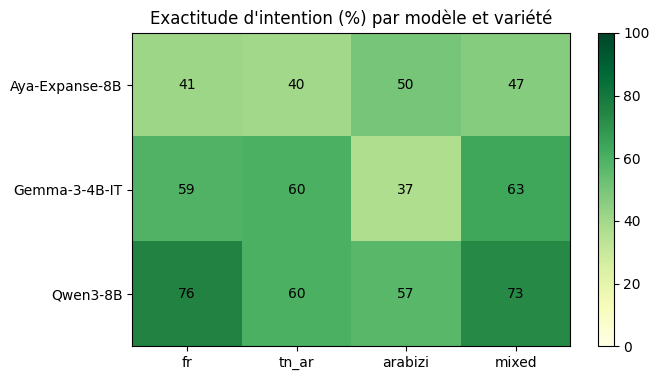

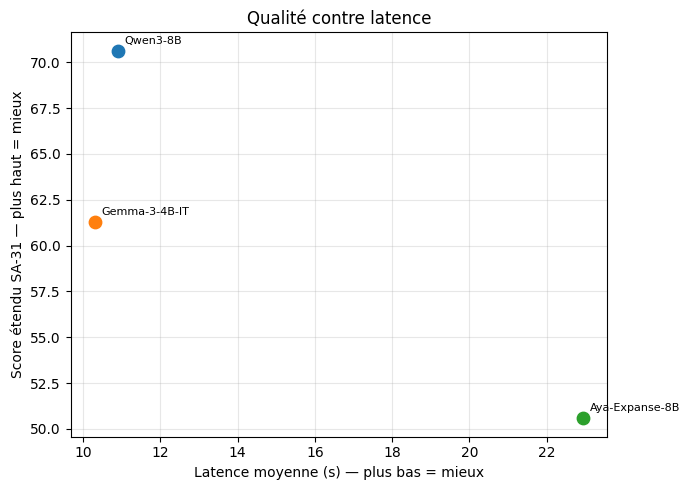

In [79]:
DEPLOY_GPU_GB = 16                 # mémoire GPU disponible au déploiement (à adapter)
REQUIRE_COMMERCIAL_LICENSE = False  # True si le chatbot sera déployé commercialement (exclut les licences NC)
EXT_WEIGHTS = {"linguistic_score": .35, "intent_macro_f1": .15, "slot_f1": .10, "calibration_score": .10,
               "answer_language_score": .10, "safety_score": .10, "json_compliance": .05, "efficiency_score": .05}
assert abs(sum(EXT_WEIGHTS.values()) - 1) < 1e-9

extended_ranking = pd.DataFrame(); sensitivity_df = pd.DataFrame()
if not decision.empty and not summary.empty:
    import matplotlib.pyplot as plt
    s = summary.set_index("model")
    ext = decision[["linguistic_score", "intent_macro_f1", "slot_f1", "json_compliance", "efficiency_score"]].copy()
    ext["calibration_score"] = 100 * (1 - s["brier"].reindex(ext.index)) if "brier" in s else np.nan
    ext["answer_language_score"] = s["answer_language_match_pct"].reindex(ext.index) if "answer_language_match_pct" in s else np.nan
    risk = s["risky_fact_rate_admission_pct"].reindex(ext.index) if "risky_fact_rate_admission_pct" in s else np.nan
    ext["safety_score"] = 100 - risk
    ext = ext.fillna(0)
    ext["SA31_extended_score"] = sum(ext[k] * w for k, w in EXT_WEIGHTS.items())

    lic = {m["name"]: m.get("license", "") for m in MODELS}
    ext["license"] = [lic.get(m, "") for m in ext.index]
    ext["peak_gpu_gb"] = s["peak_gpu_gb"].reindex(ext.index)
    ext["license_ok"] = [not (REQUIRE_COMMERCIAL_LICENSE and "NC" in str(l).upper()) for l in ext["license"]]
    ext["gpu_ok"] = ext["peak_gpu_gb"].fillna(0) <= DEPLOY_GPU_GB
    ext["eligible"] = ext.license_ok & ext.gpu_ok
    ext = ext.sort_values(["eligible", "SA31_extended_score"], ascending=[False, False])
    extended_ranking = ext.reset_index()
    print("Classement étendu (modèles éligibles en premier) :")
    show_table(extended_ranking.round(2))

    elig = ext[ext.eligible]
    if len(elig) >= 2:
        rng = np.random.default_rng(42); keys = list(EXT_WEIGHTS)
        base = np.array([EXT_WEIGHTS[k] for k in keys]); X = elig[keys].to_numpy(float)
        wins = pd.Series(0, index=elig.index); ranks = pd.DataFrame(0.0, index=elig.index, columns=["mean_rank"])
        rank_sum = np.zeros(len(elig))
        N = 2000
        for _ in range(N):
            w = base * rng.uniform(.8, 1.2, size=len(base)); w /= w.sum()
            sc = X @ w; order = (-sc).argsort()
            wins.iloc[order[0]] += 1
            r = np.empty(len(sc)); r[order] = np.arange(1, len(sc) + 1); rank_sum += r
        sensitivity_df = pd.DataFrame({"model": elig.index, "first_place_pct": 100 * wins.values / N,
                                       "mean_rank": rank_sum / N}).sort_values("first_place_pct", ascending=False)
        print("Robustesse du classement (poids variés de ±20 %) :")
        show_table(sensitivity_df.round(2))
        top = sensitivity_df.iloc[0]
        print(f"→ {top.model} arrive 1er dans {top.first_place_pct:.0f} % des tirages." +
              ("  Choix fragile : justifier aussi par la revue humaine." if top.first_place_pct < 70 else "  Choix stable."))

   
    pivot_lang = eval_df.groupby(["model", "language_expected"]).intent_correct.mean().unstack() * 100
    pivot_lang = pivot_lang.reindex(columns=[c for c in ["fr", "tn_ar", "arabizi", "mixed"] if c in pivot_lang.columns])
    fig, ax = plt.subplots(figsize=(7, 0.8 * len(pivot_lang) + 1.5))
    im = ax.imshow(pivot_lang.values, vmin=0, vmax=100, cmap="YlGn", aspect="auto")
    ax.set_xticks(range(pivot_lang.shape[1])); ax.set_xticklabels(pivot_lang.columns)
    ax.set_yticks(range(pivot_lang.shape[0])); ax.set_yticklabels(pivot_lang.index)
    for i in range(pivot_lang.shape[0]):
        for j in range(pivot_lang.shape[1]):
            ax.text(j, i, f"{pivot_lang.values[i, j]:.0f}", ha="center", va="center")
    ax.set_title("Exactitude d'intention (%) par modèle et variété"); fig.colorbar(im, ax=ax)
    fig.tight_layout(); fig.savefig(OUTPUT_DIR / "fig_intent_heatmap.png", dpi=150); plt.show()

    fig, ax = plt.subplots(figsize=(7, 5))
    lat = s["latency_mean_sec"].reindex(ext.index)
    for name in ext.index:
        ax.scatter(lat[name], ext.loc[name, "SA31_extended_score"], s=80)
        ax.annotate(name, (lat[name], ext.loc[name, "SA31_extended_score"]), textcoords="offset points", xytext=(5, 5), fontsize=8)
    ax.set_xlabel("Latence moyenne (s) — plus bas = mieux"); ax.set_ylabel("Score étendu SA-31 — plus haut = mieux")
    ax.set_title("Qualité contre latence"); ax.grid(alpha=.3)
    fig.tight_layout(); fig.savefig(OUTPUT_DIR / "fig_quality_vs_latency.png", dpi=150); plt.show()


## 16. Grille humaine de qualité (Agent Response Assessment / LLM-as-a-Judge)



In [80]:
HUMAN_REVIEW_PATH = OUTPUT_DIR / "SA33_SA34_human_review_blinded.csv"
BLIND_KEY_PATH = OUTPUT_DIR / "SA33_SA34_blind_codes_key.csv"
HUMAN_SCORE_COLS = ["relevance_1_5","language_quality_1_5","naturalness_1_5","clarity_1_5","profile_extraction_1_5","instruction_following_1_5"]
HUMAN_FLAG_COLS = ["hallucination_flag","unsupported_admission_fact_flag","irrelevant_answer_flag","dialect_mismatch_flag"]

if not eval_df.empty:
    human=eval_df[["model","case_id","language_expected","intent_expected","question","answer"]].copy()
    model_codes={name:f"Model_{i+1:02d}" for i,name in enumerate(sorted(human.model.unique()))}
    human["blind_model_code"]=human.model.map(model_codes)
    for c in HUMAN_SCORE_COLS: human[c]=np.nan
    for c in HUMAN_FLAG_COLS: human[c]=""
    human["reviewer_comment"]=""
    human=human.sample(frac=1,random_state=42).reset_index(drop=True)   # lignes mélangées : évaluation réellement à l'aveugle
    already_filled = HUMAN_REVIEW_PATH.exists() and pd.read_csv(HUMAN_REVIEW_PATH)[HUMAN_SCORE_COLS].notna().any().any()
    if already_filled:
        print("Grille humaine déjà annotée : NON écrasée (supprime le fichier pour la régénérer).")
    else:
        human.drop(columns=["model"]).to_csv(HUMAN_REVIEW_PATH,index=False)
        pd.DataFrame([{"model":k,"blind_model_code":v} for k,v in model_codes.items()]).to_csv(BLIND_KEY_PATH,index=False)
        print("Grille humaine exportée :",HUMAN_REVIEW_PATH.name)


Grille humaine exportée : SA33_SA34_human_review_blinded.csv


In [81]:
HUMAN_REVIEW_PATH=OUTPUT_DIR/"SA33_SA34_human_review_blinded.csv"
if HUMAN_REVIEW_PATH.exists():
    human_filled=pd.read_csv(HUMAN_REVIEW_PATH)
    human_cols=["relevance_1_5","language_quality_1_5","naturalness_1_5","clarity_1_5","profile_extraction_1_5","instruction_following_1_5"]
    if human_filled[human_cols].notna().any().any():
        human_filled["human_score_100"]=human_filled[human_cols].mean(axis=1)*20
        human_summary=human_filled.groupby("blind_model_code")["human_score_100"].mean().reset_index()
        if os.path.exists(str(OUTPUT_DIR/"SA33_SA34_blind_codes_key.csv")):
            human_summary=human_summary.merge(pd.read_csv(str(OUTPUT_DIR/"SA33_SA34_blind_codes_key.csv")),on="blind_model_code",how="left")
        print("Résultats de revue humaine :")
        show_table(human_summary.sort_values("human_score_100",ascending=False).round(2))
        flag_cols=["hallucination_flag","unsupported_admission_fact_flag","irrelevant_answer_flag","dialect_mismatch_flag"]
        if all(c in human_filled.columns for c in flag_cols):
            for c in flag_cols:
                human_filled[c]=human_filled[c].astype(str).str.lower().isin(["true","1","yes","oui"])
            human_errors=human_filled.groupby("blind_model_code")[flag_cols].sum().reset_index()
            if os.path.exists(str(OUTPUT_DIR/"SA33_SA34_blind_codes_key.csv")):
                human_errors=human_errors.merge(pd.read_csv(str(OUTPUT_DIR/"SA33_SA34_blind_codes_key.csv")),on="blind_model_code",how="left")
            print("Drapeaux d'erreurs qualitatifs détectés par les évaluateurs :")
            show_table(human_errors)
    else:
        print("La grille humaine est encore vide : remplir les notes puis relancer cette cellule.")

La grille humaine est encore vide : remplir les notes puis relancer cette cellule.


In [82]:

REVIEWER2_PATH = OUTPUT_DIR / "SA33_SA34_human_review_blinded_reviewer2.csv"
if HUMAN_REVIEW_PATH.exists() and REVIEWER2_PATH.exists():
    from sklearn.metrics import cohen_kappa_score
    r1 = pd.read_csv(HUMAN_REVIEW_PATH); r2 = pd.read_csv(REVIEWER2_PATH)
    both = r1.merge(r2, on=["blind_model_code", "case_id"], suffixes=("_1", "_2"))
    kap = []
    for c in HUMAN_SCORE_COLS:
        d = both[[f"{c}_1", f"{c}_2"]].dropna()
        if len(d) >= 5:
            kap.append({"criterion": c, "n": len(d),
                        "weighted_kappa": cohen_kappa_score(d.iloc[:, 0].astype(int), d.iloc[:, 1].astype(int), weights="quadratic")})
    if kap:
        print("Accord inter-évaluateurs (kappa pondéré ; > 0,6 = bon) :"); show_table(pd.DataFrame(kap).round(3))
else:
    print("Kappa : ajouter le fichier du 2e évaluateur (", REVIEWER2_PATH.name, ") pour mesurer l'accord.")


Kappa : ajouter le fichier du 2e évaluateur ( SA33_SA34_human_review_blinded_reviewer2.csv ) pour mesurer l'accord.


## 17. Décision finale SA-31 à documenter


In [84]:
DECISION_SA31={
    "selected_model":"A_COMPLETER_APRES_LECTURE_DES_RESULTATS",
    "backup_model":"A_COMPLETER",
    "reason_for_selection":"A_COMPLETER",
    "french_quality":"A_COMPLETER",
    "tunisian_arabic_quality":"A_COMPLETER",
    "arabizi_quality":"A_COMPLETER",
    "mixed_language_quality":"A_COMPLETER",
    "human_review_completed":False,
    "license_checked":False,
    "known_limitations":[],
    "decision_date":"A_COMPLETER"
}
print(json.dumps(DECISION_SA31,ensure_ascii=False,indent=2))

{
  "selected_model": "A_COMPLETER_APRES_LECTURE_DES_RESULTATS",
  "backup_model": "A_COMPLETER",
  "reason_for_selection": "A_COMPLETER",
  "french_quality": "A_COMPLETER",
  "tunisian_arabic_quality": "A_COMPLETER",
  "arabizi_quality": "A_COMPLETER",
  "mixed_language_quality": "A_COMPLETER",
  "human_review_completed": false,
  "license_checked": false,
  "known_limitations": [],
  "decision_date": "A_COMPLETER"
}


## 18. Exports CSV et preuves du backlog


In [85]:

question_bank.to_csv(OUTPUT_DIR/"SA32_question_bank_180.csv",index=False)
if not raw_df.empty: raw_df.to_csv(OUTPUT_DIR/"SA33_raw_model_responses.csv",index=False)
if not eval_df.empty: eval_df.to_csv(OUTPUT_DIR/"SA33_evaluation_details.csv",index=False)
if not summary.empty: summary.to_csv(OUTPUT_DIR/"SA33_comparison_summary.csv",index=False)
if not status_df.empty: status_df.to_csv(OUTPUT_DIR/"SA33_model_execution_status.csv",index=False)
if not fallback_df.empty: fallback_df.to_csv(OUTPUT_DIR/"SA34_fallback_recovery_results.csv",index=False)
if not decision.empty: decision.to_csv(OUTPUT_DIR/"SA31_model_selection_ranking.csv")
_extras = {"SA33_extra_metrics.csv":"extra_metrics","SA33_bootstrap_ci.csv":"ci_df","SA33_pairwise_mcnemar.csv":"mcnemar_df",
           "SA33_latency_by_language.csv":"lat_lang","SA34_semantic_similarity.csv":"semantic_df",
           "SA34_fallback_trigger_quality.csv":"trigger_quality","SA31_extended_ranking.csv":"extended_ranking",
           "SA31_weight_sensitivity.csv":"sensitivity_df"}
for _fname,_var in _extras.items():
    _df = globals().get(_var)
    if isinstance(_df,pd.DataFrame) and not _df.empty: _df.to_csv(OUTPUT_DIR/_fname,index=False)

import hashlib, datetime
from importlib import metadata
def _ver(p):
    try: return metadata.version(p)
    except Exception: return None
manifest = {
    "date_utc": datetime.datetime.utcnow().isoformat(timespec="seconds"),
    "python": platform.python_version(),
    "packages": {p:_ver(p) for p in ["torch","transformers","huggingface_hub","bitsandbytes","accelerate","pandas","numpy","scikit-learn","scipy","bert-score","peft"]},
    "gpus": [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())] if torch.cuda.is_available() else [],
    "settings": {"QUICK_RUN":QUICK_RUN,"LOAD_IN_4BIT":LOAD_IN_4BIT,"MAX_NEW_TOKENS":MAX_NEW_TOKENS,"MAX_INPUT_TOKENS":MAX_INPUT_TOKENS,
                 "DO_SAMPLE":DO_SAMPLE,"FALLBACK_CONFIDENCE_THRESHOLD":FALLBACK_CONFIDENCE_THRESHOLD,
                 "SECOND_PASS_ON_ALL_DIALECT_CASES":SECOND_PASS_ON_ALL_DIALECT_CASES,"SELECTED_MODEL_NAME":SELECTED_MODEL_NAME,
                 "EXT_WEIGHTS":globals().get("EXT_WEIGHTS")},
    "system_prompt_sha256": hashlib.sha256(SYSTEM_PROMPT.encode("utf-8")).hexdigest(),
    "question_bank_sha256": hashlib.sha256(question_bank.to_csv(index=False).encode("utf-8")).hexdigest(),
    "models": [{"name":m["name"],"hf_id":m["hf_id"],"license":m.get("license")} for m in MODELS_TO_RUN],
}
(OUTPUT_DIR/"run_manifest.json").write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding="utf-8")

print("Exports disponibles dans",OUTPUT_DIR,":")
for path in sorted(OUTPUT_DIR.glob("SA*.csv")):
    print(path.name, f"({path.stat().st_size/1024:.1f} KB)")


import zipfile
zip_path = OUTPUT_DIR / "smartcampus_benchmark_csv.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for pattern in ("*.csv","*.png","run_manifest.json"):
        for path in sorted(OUTPUT_DIR.glob(pattern)):
            if not path.name.endswith("_checkpoint.csv"):
                zf.write(path, path.name)
print("Archive :", zip_path.name, f"({zip_path.stat().st_size/1024:.0f} KB)")

cmds = ["# pip install -U \"huggingface_hub<1.0\" hf_xet", "# Modèles gated : accepter la licence sur Hugging Face + définir HF_TOKEN", ""]
for m in MODELS_TO_RUN:
    cmds.append(f'huggingface-cli download {m["hf_id"]} --local-dir "SmartCampusModels/{m["name"]}"')
(OUTPUT_DIR / "download_models_commands.txt").write_text("\n".join(cmds), encoding="utf-8")
print("Commandes de téléchargement des modèles :")
print("\n".join(cmds))


Exports disponibles dans /kaggle/working :
SA31_extended_ranking.csv (0.8 KB)
SA31_model_selection_ranking.csv (0.4 KB)
SA31_weight_sensitivity.csv (0.1 KB)
SA32_question_bank_180.csv (54.0 KB)
SA32_question_validation_template.csv (52.9 KB)
SA33_SA34_blind_codes_key.csv (0.1 KB)
SA33_SA34_human_review_blinded.csv (362.0 KB)
SA33_bootstrap_ci.csv (0.5 KB)
SA33_comparison_summary.csv (3.0 KB)
SA33_evaluation_details.csv (993.5 KB)
SA33_extra_metrics.csv (1.3 KB)
SA33_latency_by_language.csv (0.7 KB)
SA33_model_execution_status.csv (0.8 KB)
SA33_model_execution_status_checkpoint.csv (0.8 KB)
SA33_pairwise_mcnemar.csv (0.4 KB)
SA33_raw_model_responses.csv (593.1 KB)
SA33_raw_model_responses_checkpoint.csv (593.1 KB)
SA34_dialect_error_analysis.csv (15.4 KB)
SA34_fallback_recovery_results.csv (58.3 KB)
SA34_fallback_trigger_quality.csv (0.3 KB)
SA34_semantic_similarity.csv (38.9 KB)
Archive : smartcampus_benchmark_csv.zip (515 KB)
Commandes de téléchargement des modèles :
# pip install -U 